### Importing all the files from S1 to S13 into a single DF:

In [1]:
# Imports:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Folder with the CSV files (raw string so the backslashes are read correctly)
data_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\MQ3_logs_S1-S13")

frames = []
skipped = []

for f in sorted(data_dir.glob("*.csv")):   # only files in this folder, not subfolders
    # Split into at most 5 parts, so yt_ext stays intact even if it contains "_"
    parts = f.stem.split("_", 4)
    if len(parts) != 5:
        skipped.append(f.name)
        continue

    set_id, vd_id, init_soc, user_state, yt_ext = parts

    df = pd.read_csv(f)              # e.g. for filename "S12_V2_95_SQ_G-XZhKqQAHU" 
    df["set_id"] = set_id            # e.g. "S12"
    df["vd_id"] = vd_id              # e.g. "V2"
    df["init_soc"] = int(init_soc)   # e.g. 95 (as a number)
    df["user_state"] = user_state    # e.g. "SQ"
    df["yt_ext"] = yt_ext            # e.g. "G-XZhKqQAHU"
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

print(f"Loaded {len(frames)} files, {len(df_all)} rows, {df_all.shape[1]} columns")
if skipped:
    print("Skipped (unexpected file name):", skipped)

df_all.head()

Loaded 70 files, 21707 rows, 46 columns


,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source,set_id,vd_id,init_soc,user_state,yt_ext
0,30,2026-10-13 18:31:42,29.61,99,4215,32.0,4953606,1701.79,7173.04,74.763,...,Running,1,0.3,00:00,manual clock,S10,V1,100,ST,KGerjHMa90s
1,31,2026-10-13 18:31:43,30.62,99,4215,32.0,4953606,1701.79,7173.04,77.731,...,Running,1,1.3,00:01,manual clock,S10,V1,100,ST,KGerjHMa90s
2,32,2026-10-13 18:31:45,32.11,99,4215,32.0,4953606,1701.79,7173.04,79.405,...,Running,1,2.8,00:02,manual clock,S10,V1,100,ST,KGerjHMa90s
3,33,2026-10-13 18:31:46,32.95,99,4215,32.0,4953606,1701.79,7173.04,81.617,...,Running,1,3.6,00:03,manual clock,S10,V1,100,ST,KGerjHMa90s
4,34,2026-10-13 18:31:47,34.06,99,4215,32.0,4953606,1701.79,7173.04,83.091,...,Running,1,4.7,00:04,manual clock,S10,V1,100,ST,KGerjHMa90s


In [3]:
combos = (
    df_all.loc[df_all["set_id"] == "S13"] # 1, 2, 3, 4, 7, 10, 11, 13
    .groupby(["set_id", "vd_id", "Video Session"], dropna=False)
    .agg(
        elapsed_min=("Elapsed (s)", "min"),
        elapsed_max=("Elapsed (s)", "max"),
        video_pos_min=("Video Position (s)", "min"),
        video_pos_max=("Video Position (s)", "max"),
    )
    .reset_index()
)

combos["Elapsed"] = combos["elapsed_max"] - combos["elapsed_min"]
combos["Video Length"] = combos["video_pos_max"] - combos["video_pos_min"]
combos["Difference"] = combos["Elapsed"] - combos["Video Length"]

print(f"{len(combos)} unique combinations")
combos

6 unique combinations


,set_id,vd_id,Video Session,elapsed_min,elapsed_max,video_pos_min,video_pos_max,Elapsed,Video Length,Difference
0,S13,V1,1,23.36,397.68,0.3,374.6,374.32,374.3,0.02
1,S13,V2,1,23.30,318.44,0.3,295.5,295.14,295.2,-0.06
2,S13,V3,1,37.31,436.79,0.7,400.2,399.48,399.5,-0.02
3,S13,V4,1,38.26,255.47,0.8,218.0,217.21,217.2,0.01
4,S13,V5,1,31.22,403.55,0.8,373.1,372.33,372.3,0.03
5,S13,V6,1,32.25,305.81,0.2,273.7,273.56,273.5,0.06


# 1. Consumption for a single video:

#### NOTE: Video 1 only shows 11 Sets (not 13) this is because it is not used in 2 Sequences Sets.

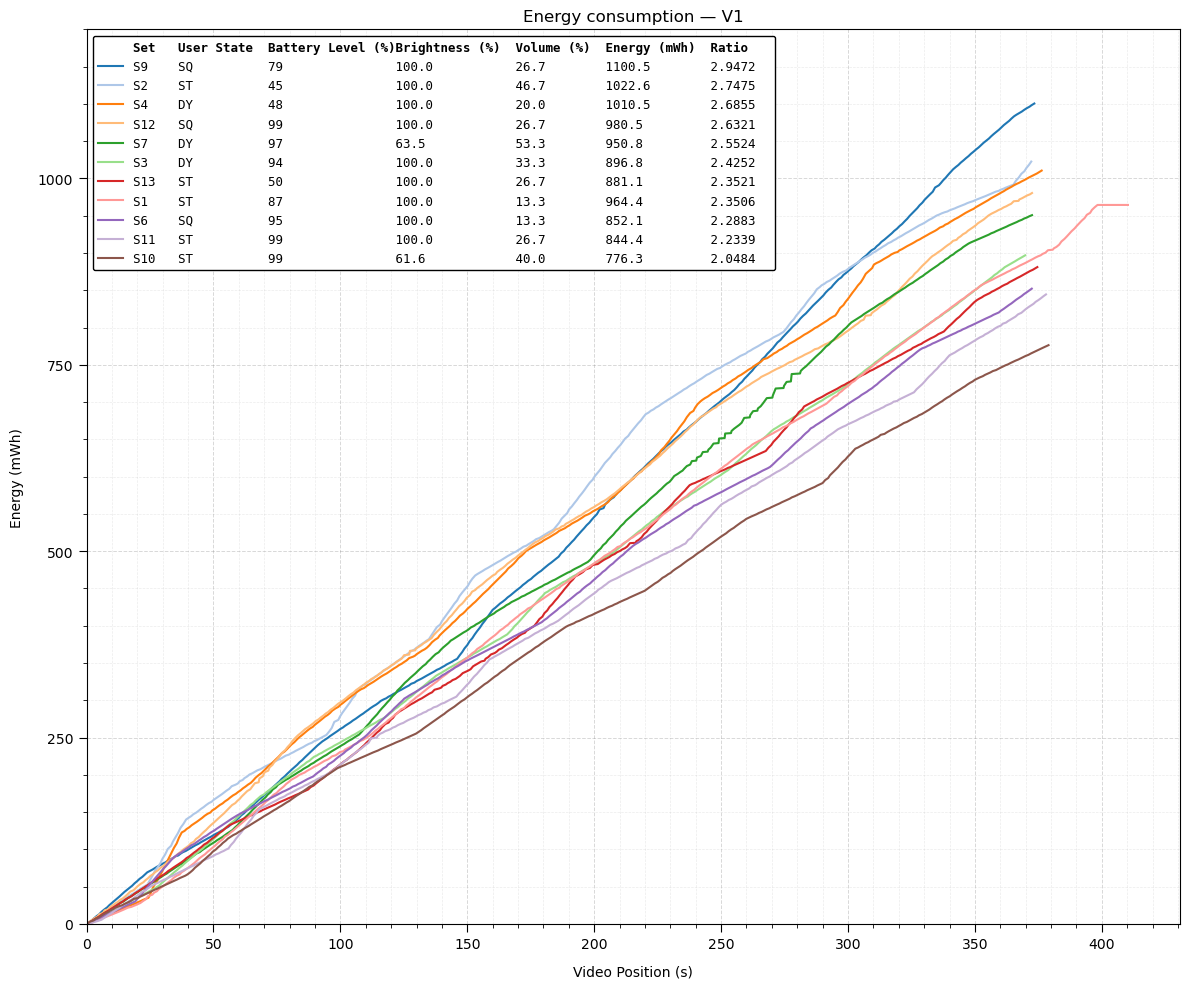

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Per-set info for the legend
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Set order by ratio, highest first
sets = info.sort_values("ratio", ascending=False).index.tolist()

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 6, "state": 12, "soc": 17, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


fig, ax = plt.subplots(figsize=(12, 10))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    r = info.loc[s]
    label = legend_row(s, r.user_state,
                       f"{r.level_max:.0f}",
                       f"{r.bright_avg:.1f}",
                       f"{r.volume_avg:.1f}",
                       f"{r.energy:.1f}",
                       f"{r.ratio:.4f}")
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=label, color=colors[i % len(colors)], linewidth=1.5)

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=10)
ax.set_ylabel("Energy (mWh)", labelpad=10)
ax.set_title("Energy consumption — V1")

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers 0, 250, 500, 750, 1000, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend inside the plot (upper left), in a box, with the header as the first row
header = legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                    "Volume (%)", "Energy (mWh)", "Ratio")
handles, labels = ax.get_legend_handles_labels()
header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

leg = ax.legend([header_handle] + handles, [header] + labels,
                loc="upper left", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")       # header row in bold

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / f"Full_Energy_consumption_V1.pdf", dpi=300, bbox_inches="tight")


plt.show()

#### RENAMED:

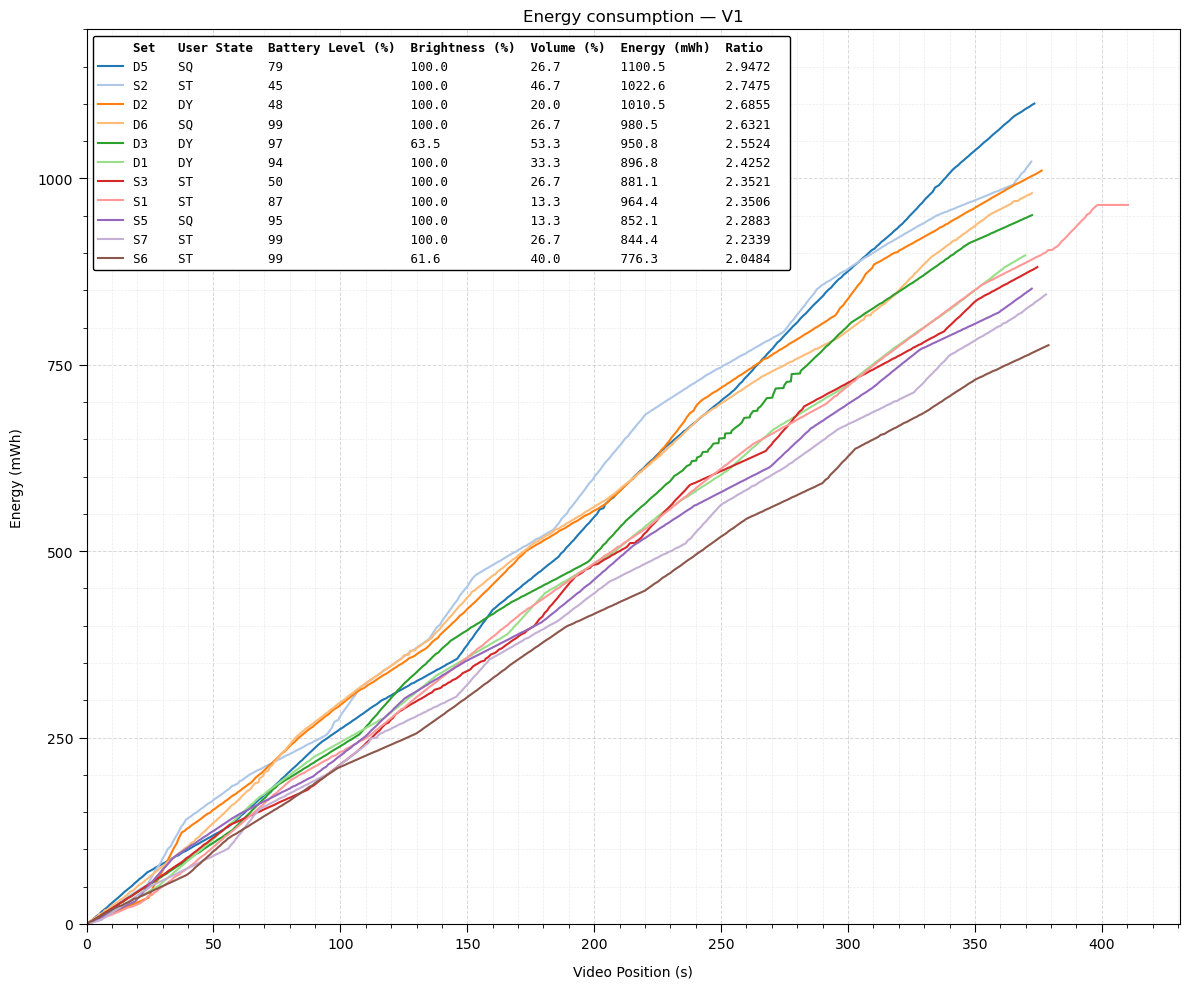

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Per-set info for the legend
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Set order by ratio, highest first
sets = info.sort_values("ratio", ascending=False).index.tolist()

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 6, "state": 12, "soc": 19, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}

# Display names for the legend (data ID -> new name)
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S5": "S4",  "S6": "S5",  "S7": "D3",  "S8": "D4",
    "S9": "D5",  "S10": "S6", "S11": "S7", "S12": "D6",
    "S13": "S3",
}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


fig, ax = plt.subplots(figsize=(12, 10))
colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets

for i, s in enumerate(sets):
    d = v1[v1["set_id"] == s]
    r = info.loc[s]
    label = legend_row(SET_RENAME.get(s, s), r.user_state,
                       f"{r.level_max:.0f}",
                       f"{r.bright_avg:.1f}",
                       f"{r.volume_avg:.1f}",
                       f"{r.energy:.1f}",
                       f"{r.ratio:.4f}")
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=label, color=colors[i % len(colors)], linewidth=1.5)

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=10)
ax.set_ylabel("Energy (mWh)", labelpad=10)
ax.set_title("Energy consumption — V1")

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers every 250, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend inside the plot (upper left), in a box, with the header as the first row
header = legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                    "Volume (%)", "Energy (mWh)", "Ratio")
handles, labels = ax.get_legend_handles_labels()
header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

leg = ax.legend([header_handle] + handles, [header] + labels,
                loc="upper left", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")       # header row in bold

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / "Full_Energy_consumption_V1.pdf", dpi=300, bbox_inches="tight")

plt.show()

#### S1 CUTTED (It goes further than others) RENAMED - lEGEND SIMPLIFIED:

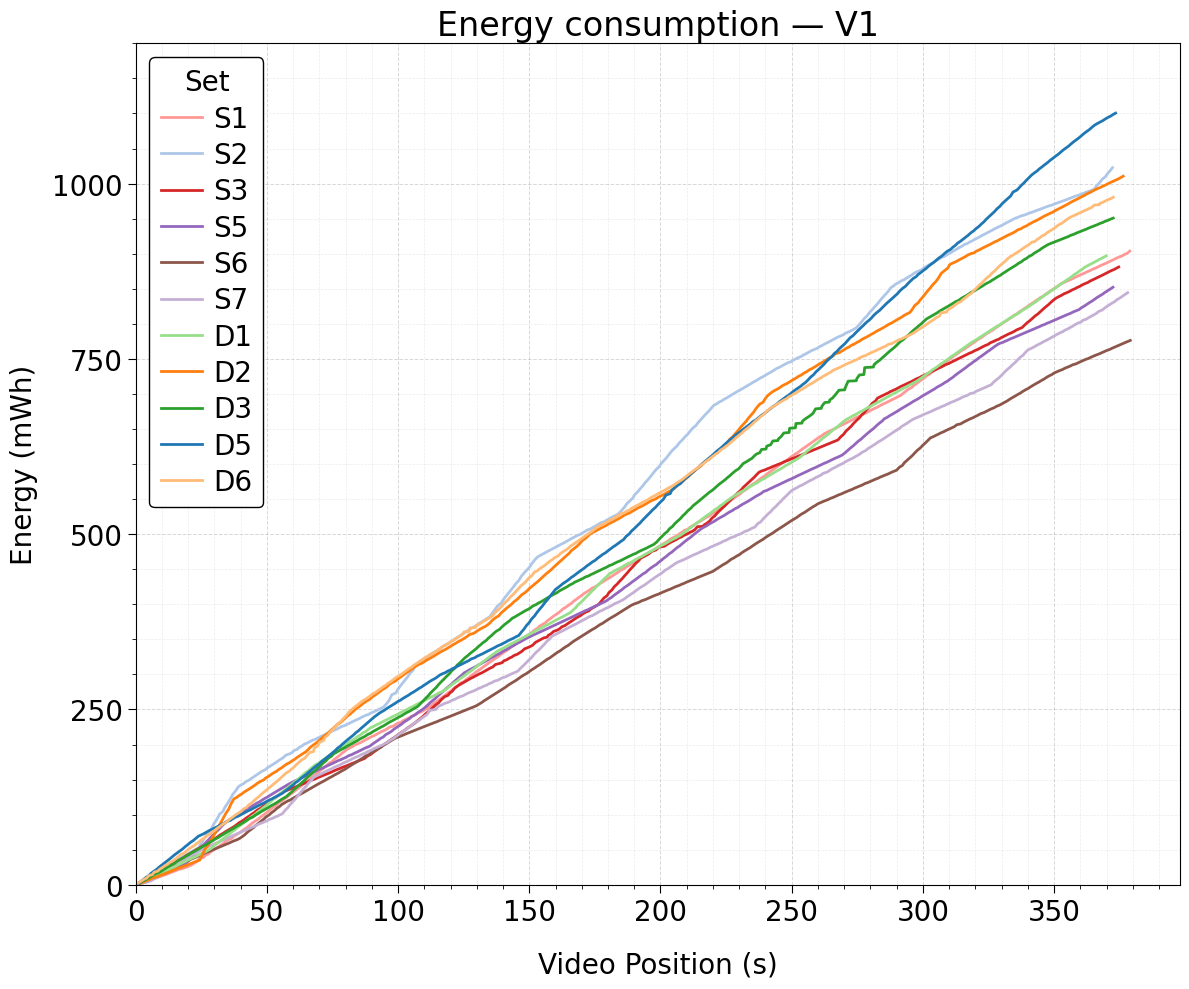

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Ratio per set (only used to keep the same colors as before: highest ratio = first color)
info = v1.groupby("set_id").agg(
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)
sets_by_ratio = info.sort_values("ratio", ascending=False).index.tolist()

colors = plt.cm.tab20.colors   # enough distinct colors for up to 20 sets
SET_COLOR = {s: colors[i % len(colors)] for i, s in enumerate(sets_by_ratio)}

# Display names for the legend (data ID -> new name)
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S5": "S4",  "S6": "S5",  "S7": "D3",  "S8": "D4",
    "S9": "D5",  "S10": "S6", "S11": "S7", "S12": "D6",
    "S13": "S3",
}

# Manual cutoff per set (seconds of video position); sets not listed are drawn in full
SET_CUTOFF = {"S1": 380}

# Font sizes (double the matplotlib defaults)
TITLE_SIZE = 24    # default ~12
LABEL_SIZE = 20    # axis titles, default 10
TICK_SIZE = 20     # numbers on the axes, default 10
LEGEND_SIZE = 20   # legend text and title, default 10

# Drawing order: S sets first, then D sets, each by their new number
sets = sorted(sets_by_ratio,
              key=lambda s: (SET_RENAME.get(s, s)[0] != "S", int(SET_RENAME.get(s, s)[1:])))

fig, ax = plt.subplots(figsize=(12, 10))

for s in sets:
    d = v1[v1["set_id"] == s]
    if s in SET_CUTOFF:                                   # trim only the listed sets
        d = d[d["Video Position (s)"] <= SET_CUTOFF[s]]
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=SET_RENAME.get(s, s), color=SET_COLOR[s], linewidth=2)

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=18, fontsize=LABEL_SIZE)
ax.set_ylabel("Energy (mWh)", labelpad=10, fontsize=LABEL_SIZE)
ax.set_title("Energy consumption — V1", fontsize=TITLE_SIZE)

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers every 250, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6, labelsize=TICK_SIZE)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend as a vertical list (S1–S7, then D1–D6)
ax.legend(title="Set", loc="upper left", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1,
          fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
          handlelength=1.5, handletextpad=0.4, labelspacing=0.3)

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / "Full_Energy_consumption_V1.pdf", dpi=300, bbox_inches="tight")

plt.show()

#### S1 CUTTED / RENAMED - lEGEND SIMPLIFIED / ONLY S1, S2, S3, D1, D2, D3:

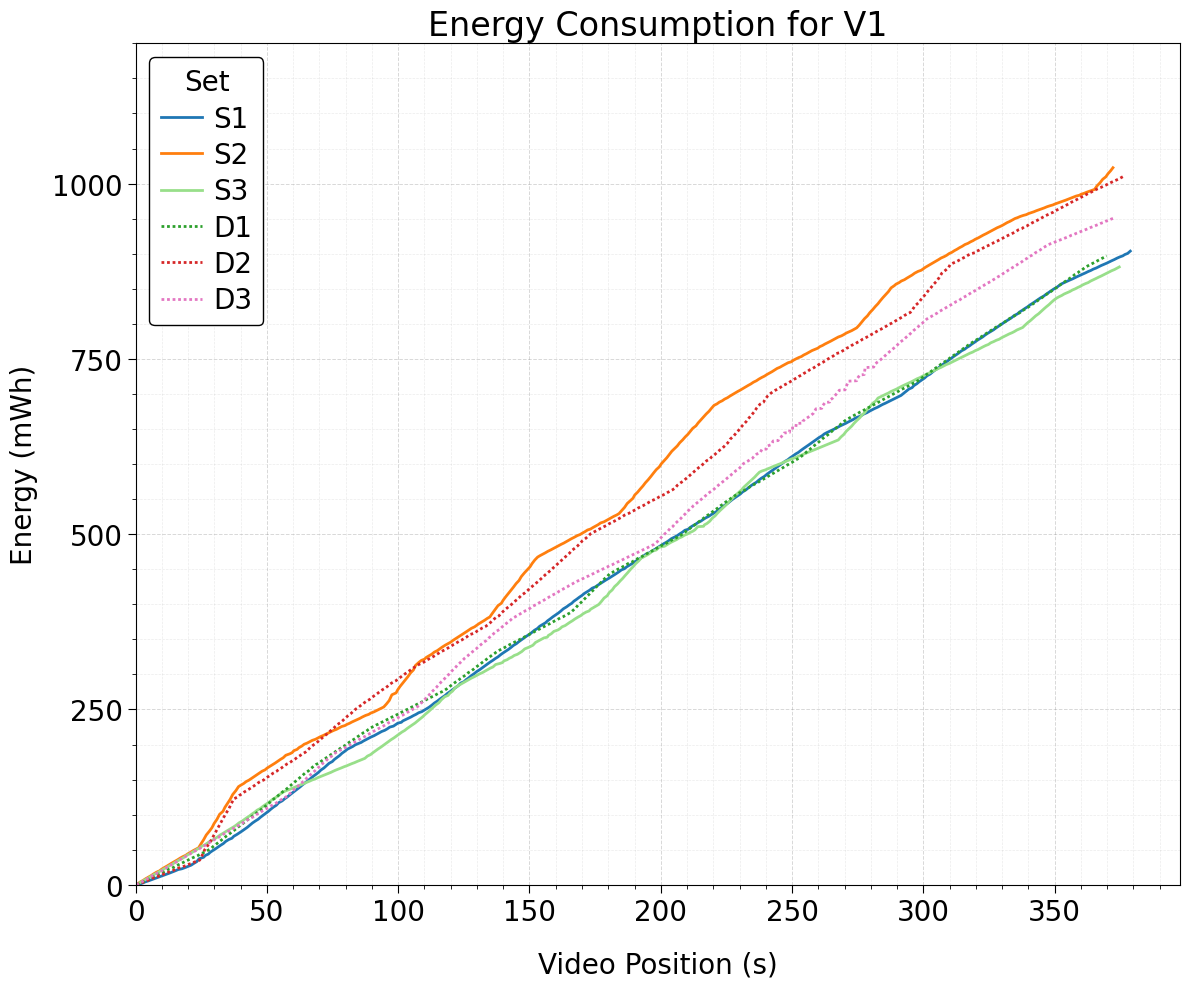

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Display names for the legend (data ID -> new name); only these sets are drawn
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S7": "D3",  "S13": "S3",
}

# Colors by new name (cool colors for S sets, warm colors for D sets)

SET_COLOR = {s: NAME_COLORS[SET_RENAME[s]] for s in SET_RENAME}

# Line style by new name; sets not listed are drawn solid
#   "-" solid, "--" dashed, ":" dotted, (0, (1, 1)) small dense dots
NAME_COLORS = {
    "S1": "#1F77B4",   # blue
    "S2": "#FF7F0E",   # orange
    "S3": "#98DF8A",   # light green
    "D1": "#2CA02C",   # green
    "D2": "#D62728",   # red
    "D3": "#E377C2",   # pink
}

# Manual cutoff per set (seconds of video position); sets not listed are drawn in full
SET_CUTOFF = {"S1": 380}

# Font sizes (double the matplotlib defaults)
TITLE_SIZE = 24    # default ~12
LABEL_SIZE = 20    # axis titles, default 10
TICK_SIZE = 20     # numbers on the axes, default 10
LEGEND_SIZE = 20   # legend text and title, default 10

# Drawing order: S sets first, then D sets, each by their new number
sets = sorted(SET_RENAME, key=lambda s: (SET_RENAME[s][0] != "S", int(SET_RENAME[s][1:])))

fig, ax = plt.subplots(figsize=(12, 10))

for s in sets:
    d = v1[v1["set_id"] == s]
    if s in SET_CUTOFF:                                   # trim only the listed sets
        d = d[d["Video Position (s)"] <= SET_CUTOFF[s]]
    name = SET_RENAME[s]
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=name, color=SET_COLOR[s], linewidth=2,
            linestyle=NAME_STYLES.get(name, "-"))

# Axis titles a bit further from their axes
ax.set_xlabel("Video Position (s)", labelpad=18, fontsize=LABEL_SIZE)
ax.set_ylabel("Energy (mWh)", labelpad=10, fontsize=LABEL_SIZE)
ax.set_title("Energy Consumption for V1", fontsize=TITLE_SIZE)

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers every 250, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6, labelsize=TICK_SIZE)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend as a vertical list (S1–S3, then D1–D3)
ax.legend(title="Set", loc="upper left", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1,
          fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
          handlelength=1.5, handletextpad=0.4, labelspacing=0.3)

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / "Full_Energy_consumption_V1_v2.pdf", dpi=300, bbox_inches="tight")

plt.show()

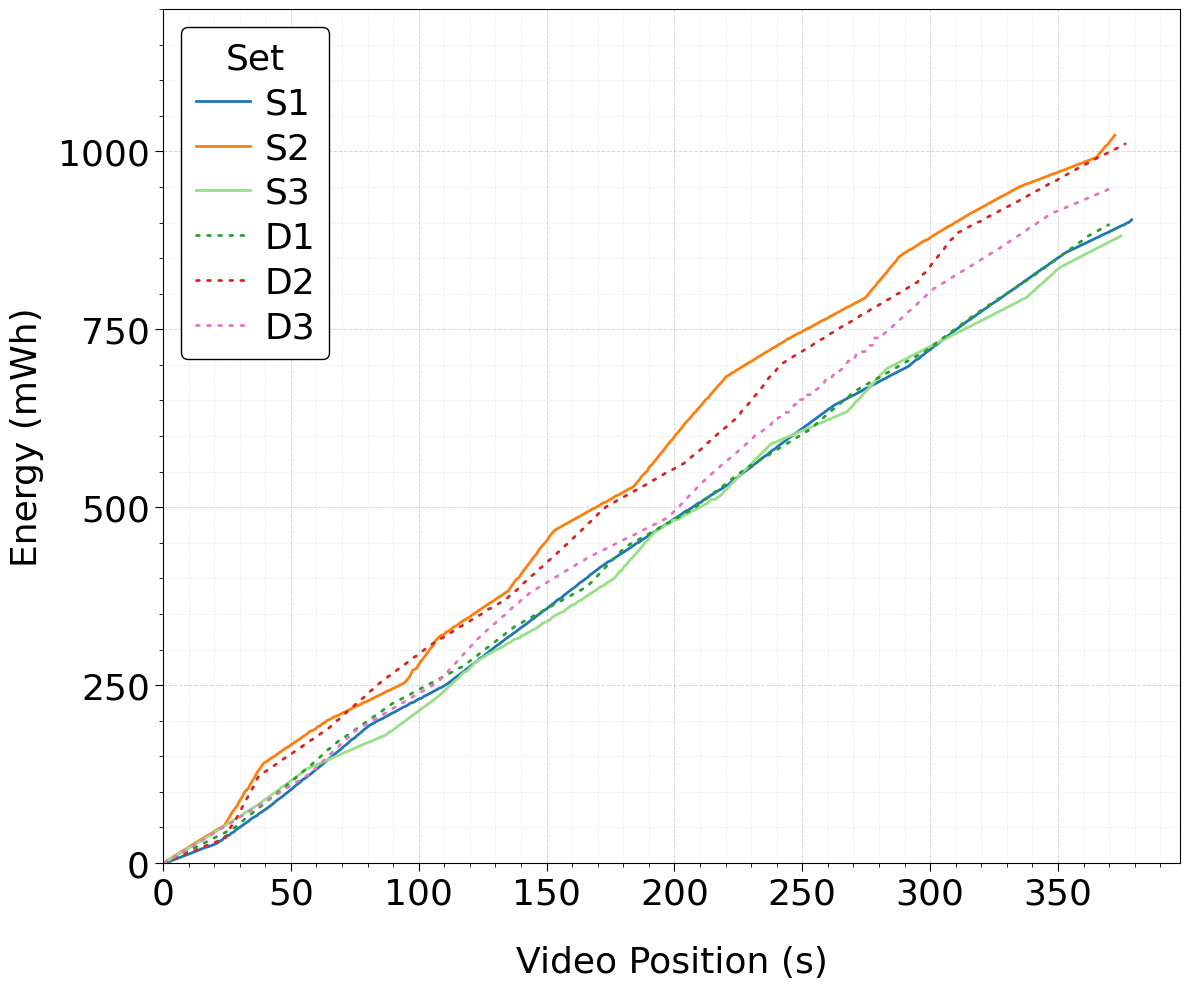

In [50]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import MultipleLocator

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Shift each set's accumulated power so its first value is 0
v1["Accumulated Power from start (mWh)"] = (
    v1["Accumulated Power (mWh)"]
    - v1.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
)

# Display names for the legend (data ID -> new name); only these sets are drawn
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S7": "D3",  "S13": "S3",
}

# Colors by new name
NAME_COLORS = {
    "S1": "#1F77B4",   # blue
    "S2": "#FF7F0E",   # orange
    "S3": "#98DF8A",   # light green
    "D1": "#2CA02C",   # green
    "D2": "#D62728",   # red
    "D3": "#E377C2",   # pink
}
SET_COLOR = {s: NAME_COLORS[SET_RENAME[s]] for s in SET_RENAME}

# Line style by new name; sets not listed are drawn solid
#   (0, (1, 3)) = dots with wider spacing; raise the 3 for more space between dots
DOTTED = (0, (1, 3))
NAME_STYLES = {"D1": DOTTED, "D2": DOTTED, "D3": DOTTED}

# Manual cutoff per set (seconds of video position); sets not listed are drawn in full
SET_CUTOFF = {"S1": 380}

# Font sizes (1.3x the previous 20)
LABEL_SIZE = 26    # axis titles
TICK_SIZE = 26     # numbers on the axes
LEGEND_SIZE = 26   # legend text and title

# Drawing order: S sets first, then D sets, each by their new number
sets = sorted(SET_RENAME, key=lambda s: (SET_RENAME[s][0] != "S", int(SET_RENAME[s][1:])))

fig, ax = plt.subplots(figsize=(12, 10))

for s in sets:
    d = v1[v1["set_id"] == s]
    if s in SET_CUTOFF:                                   # trim only the listed sets
        d = d[d["Video Position (s)"] <= SET_CUTOFF[s]]
    name = SET_RENAME[s]
    ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
            label=name, color=SET_COLOR[s], linewidth=2,
            linestyle=NAME_STYLES.get(name, "-"),
            dash_capstyle="round")                        # round dots

# Axis titles further from their axes
ax.set_xlabel("Video Position (s)", labelpad=25, fontsize=LABEL_SIZE)
ax.set_ylabel("Energy (mWh)", labelpad=10, fontsize=LABEL_SIZE)

# X-axis: numbers every 50, unnumbered ticks every 10
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(10))

# Y-axis: numbers every 250, unnumbered ticks every 50
ax.set_ylim(0, 1200)
ax.yaxis.set_major_locator(MultipleLocator(250))
ax.yaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6, labelsize=TICK_SIZE)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend as a vertical list (S1–S3, then D1–D3)
ax.legend(title="Set", loc="upper left", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1,
          fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
          handlelength=1.5, handletextpad=0.4, labelspacing=0.3)

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

fig.savefig(out_dir / "Full_Energy_consumption_V1_v2.pdf", dpi=300, bbox_inches="tight")

plt.show()

#### PREVOUS ONE USING LAMBDA FOR VIDEO LENGTH (MORE ACCURATED):

,Set,User State,Battery Level (%),Brightness (%),Volume (%),Energy (mWh),Ratio
0,D5,Dynamic Sequence,79,100.0,26.7,1100.5,2.9543
1,S2,Static,45,100.0,46.7,1022.6,2.7512
2,D2,Dynamic,48,100.0,20.0,1010.5,2.6876
3,D6,Dynamic Sequence,99,100.0,26.7,980.5,2.6335
4,D3,Dynamic,97,63.5,53.3,950.8,2.5544
5,D1,Dynamic,94,100.0,33.3,896.8,2.4292
6,S1,Static,87,100.0,13.3,964.4,2.3546
7,S3,Static,50,100.0,26.7,881.1,2.3540
8,S5,Static Sequence,95,100.0,13.3,852.1,2.2895
9,S7,Static,99,100.0,26.7,844.4,2.2398


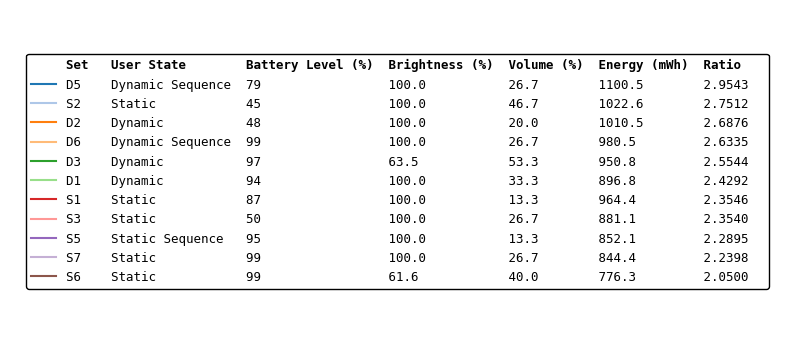

#### PREVOUS ONE USING LAMBDA FOR VIDEO LENGTH (MORE ACCURATED):

,Set,User State,Battery Level (%),Brightness (%),Volume (%),Energy (mWh),Ratio
0,D5,Dynamic Sequence,79,100.0,26.7,1100.5,2.9543
1,S2,Static,45,100.0,46.7,1022.6,2.7512
2,D2,Dynamic,48,100.0,20.0,1010.5,2.6876
3,D6,Dynamic Sequence,99,100.0,26.7,980.5,2.6335
4,D3,Dynamic,97,63.5,53.3,950.8,2.5544
5,D1,Dynamic,94,100.0,33.3,896.8,2.4292
6,S1,Static,87,100.0,13.3,964.4,2.3546
7,S3,Static,50,100.0,26.7,881.1,2.3540
8,S5,Static Sequence,95,100.0,13.3,852.1,2.2895
9,S7,Static,99,100.0,26.7,844.4,2.2398


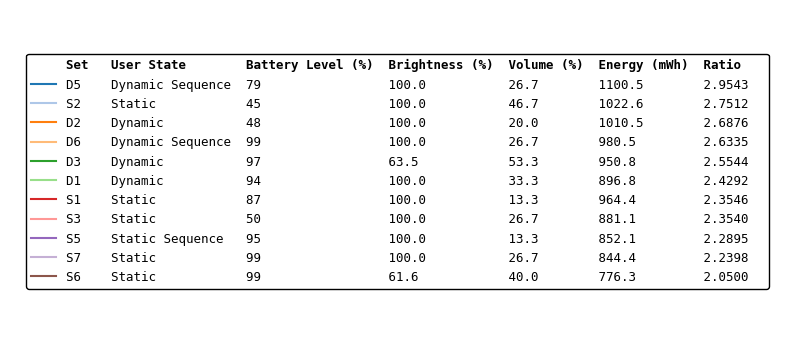

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Per-set info (same calculation as in the graph)
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    video_length=("Video Position (s)", lambda p: p.max() - p.min()),   # recorded duration
)

# Ratio: energy per second of recorded video (zero length -> NaN)
info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

# Display names (data ID -> new name)
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S5": "S4",  "S6": "S5",  "S7": "D3",  "S8": "D4",
    "S9": "D5",  "S10": "S6", "S11": "S7", "S12": "D6",
    "S13": "S3",
}
info["set_name"] = [SET_RENAME.get(s, s) for s in info.index]


def state_label(state, set_name):
    """ST -> Static, DY -> Dynamic, SQ -> Static/Dynamic Sequence (by the set's first letter)."""
    if state == "ST":
        return "Static"
    if state == "DY":
        return "Dynamic"
    if state == "SQ":
        return "Dynamic Sequence" if set_name.startswith("D") else "Static Sequence"
    return state


info["state_name"] = [state_label(st, nm) for st, nm in zip(info["user_state"], info["set_name"])]

# Same order and colors as in the graph: ratio, highest first
info = info.sort_values("ratio", ascending=False)
colors = plt.cm.tab20.colors
info["color"] = [colors[i % len(colors)] for i in range(len(info))]

# ---------- 1) As a pandas table ----------
table = pd.DataFrame({
    "Set": info["set_name"],
    "User State": info["state_name"],
    "Battery Level (%)": info["level_max"].round(0),
    "Brightness (%)": info["bright_avg"].round(1),
    "Volume (%)": info["volume_avg"].round(1),
    "Energy (mWh)": info["energy"].round(1),
    "Ratio": info["ratio"].round(4),
}).reset_index(drop=True)
display(table)

# ---------- 2) As a legend-only figure (same look as the graph's legend) ----------
# Legend column widths (characters); "state" widened to fit "Dynamic Sequence"
COL_W = {"set": 6, "state": 18, "soc": 19, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


handles = [Line2D([], [], color="none")]   # invisible sample for the header row
labels = [legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                     "Volume (%)", "Energy (mWh)", "Ratio")]
for _, r in info.iterrows():
    handles.append(Line2D([], [], color=r.color, linewidth=1.5))
    labels.append(legend_row(r.set_name, r.state_name,
                             f"{r.level_max:.0f}",
                             f"{r.bright_avg:.1f}",
                             f"{r.volume_avg:.1f}",
                             f"{r.energy:.1f}",
                             f"{r.ratio:.4f}"))

fig, ax = plt.subplots(figsize=(10, 0.3 * len(handles) + 0.6))
ax.axis("off")   # no axes, ticks or plot area
leg = ax.legend(handles, labels, loc="center", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")   # header row in bold

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Full_Energy_consumption_V1_Table.pdf", dpi=300, bbox_inches="tight")

plt.show()

#### RENAMED - ONLY TABLE:

,Set,User State,Battery Level (%),Brightness (%),Volume (%),Energy (mWh),Ratio
0,D5,Dynamic Sequence,79,100.0,26.7,1100.5,2.9472
1,S2,Static,45,100.0,46.7,1022.6,2.7475
2,D2,Dynamic,48,100.0,20.0,1010.5,2.6855
3,D6,Dynamic Sequence,99,100.0,26.7,980.5,2.6321
4,D3,Dynamic,97,63.5,53.3,950.8,2.5524
5,D1,Dynamic,94,100.0,33.3,896.8,2.4252
6,S3,Static,50,100.0,26.7,881.1,2.3521
7,S1,Static,87,100.0,13.3,964.4,2.3506
8,S5,Static Sequence,95,100.0,13.3,852.1,2.2883
9,S7,Static,99,100.0,26.7,844.4,2.2339


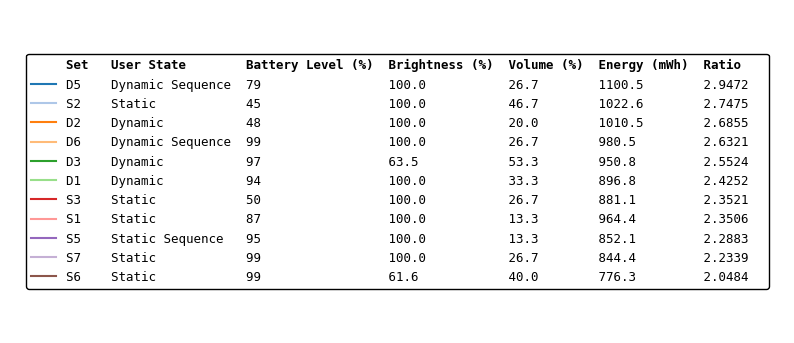

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

v1 = df_all[df_all["vd_id"] == "V1"].copy()

# Per-set info (same calculation as in the graph)
info = v1.groupby("set_id").agg(
    level_max=("Level (%)", "max"),
    user_state=("user_state", "first"),
    bright_avg=("Brightness (%)", "mean"),
    volume_avg=("Volume (%)", "mean"),
    energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
    length_max=("Video Position (s)", "max"),
)

# Ratio: energy per second of video (zero length -> NaN)
info["ratio"] = info["energy"] / info["length_max"].replace(0, np.nan)

# Display names (data ID -> new name)
SET_RENAME = {
    "S1": "S1",  "S2": "S2",  "S3": "D1",  "S4": "D2",
    "S5": "S4",  "S6": "S5",  "S7": "D3",  "S8": "D4",
    "S9": "D5",  "S10": "S6", "S11": "S7", "S12": "D6",
    "S13": "S3",
}
info["set_name"] = [SET_RENAME.get(s, s) for s in info.index]


def state_label(state, set_name):
    """ST -> Static, DY -> Dynamic, SQ -> Static/Dynamic Sequence (by the set's first letter)."""
    if state == "ST":
        return "Static"
    if state == "DY":
        return "Dynamic"
    if state == "SQ":
        return "Dynamic Sequence" if set_name.startswith("D") else "Static Sequence"
    return state


info["state_name"] = [state_label(st, nm) for st, nm in zip(info["user_state"], info["set_name"])]

# Same order and colors as in the graph: ratio, highest first
info = info.sort_values("ratio", ascending=False)
colors = plt.cm.tab20.colors
info["color"] = [colors[i % len(colors)] for i in range(len(info))]

# ---------- 1) As a pandas table ----------
table = pd.DataFrame({
    "Set": info["set_name"],
    "User State": info["state_name"],
    "Battery Level (%)": info["level_max"].round(0),
    "Brightness (%)": info["bright_avg"].round(1),
    "Volume (%)": info["volume_avg"].round(1),
    "Energy (mWh)": info["energy"].round(1),
    "Ratio": info["ratio"].round(4),
}).reset_index(drop=True)
display(table)

# ---------- 2) As a legend-only figure (same look as the graph's legend) ----------
# Legend column widths (characters); "state" widened to fit "Dynamic Sequence"
COL_W = {"set": 6, "state": 18, "soc": 19, "bright": 16, "volume": 12, "energy": 14, "ratio": 8}


def legend_row(set_txt, state, soc, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{state:<{COL_W['state']}}"
            f"{soc:<{COL_W['soc']}}{bright:<{COL_W['bright']}}"
            f"{volume:<{COL_W['volume']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


handles = [Line2D([], [], color="none")]   # invisible sample for the header row
labels = [legend_row("Set", "User State", "Battery Level (%)", "Brightness (%)",
                     "Volume (%)", "Energy (mWh)", "Ratio")]
for _, r in info.iterrows():
    handles.append(Line2D([], [], color=r.color, linewidth=1.5))
    labels.append(legend_row(r.set_name, r.state_name,
                             f"{r.level_max:.0f}",
                             f"{r.bright_avg:.1f}",
                             f"{r.volume_avg:.1f}",
                             f"{r.energy:.1f}",
                             f"{r.ratio:.4f}"))

fig, ax = plt.subplots(figsize=(10, 0.3 * len(handles) + 0.6))
ax.axis("off")   # no axes, ticks or plot area
leg = ax.legend(handles, labels, loc="center", frameon=True,
                facecolor="white", edgecolor="black", framealpha=1,
                prop={"family": "monospace", "size": 9})
leg.get_texts()[0].set_fontweight("bold")   # header row in bold

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Full_Energy_consumption_V1_Table.pdf", dpi=300, bbox_inches="tight")

plt.show()

# 2. Consumption for ALL videos (exclusing some Sets):

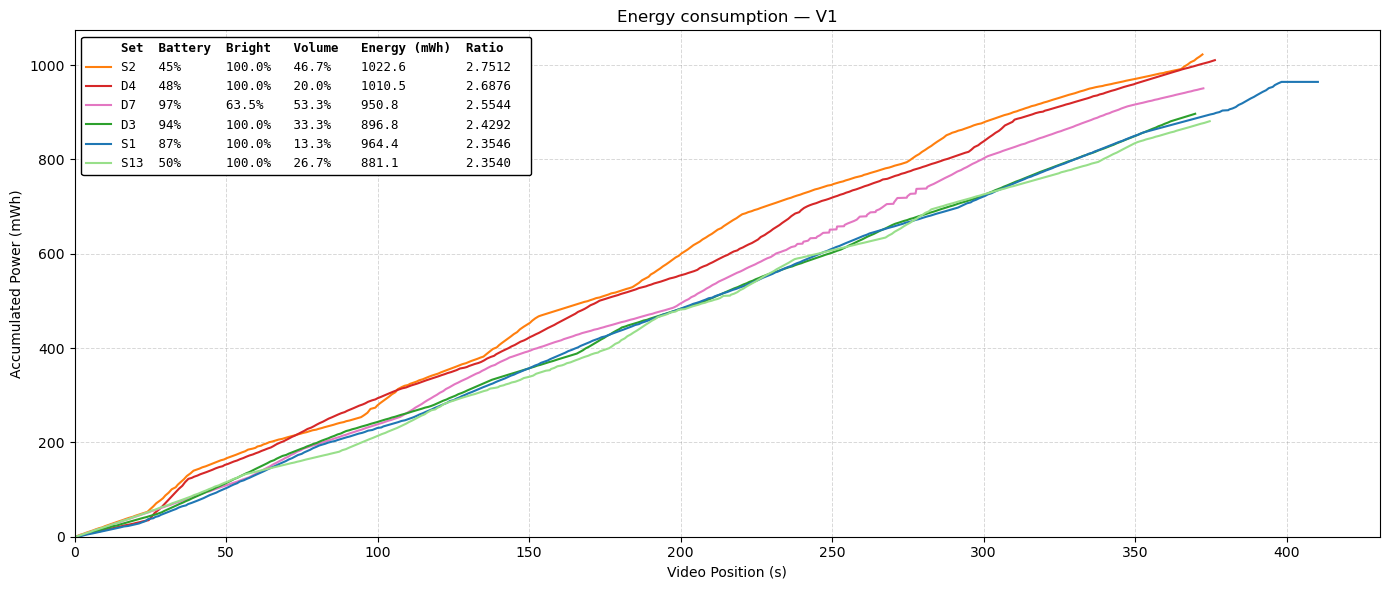

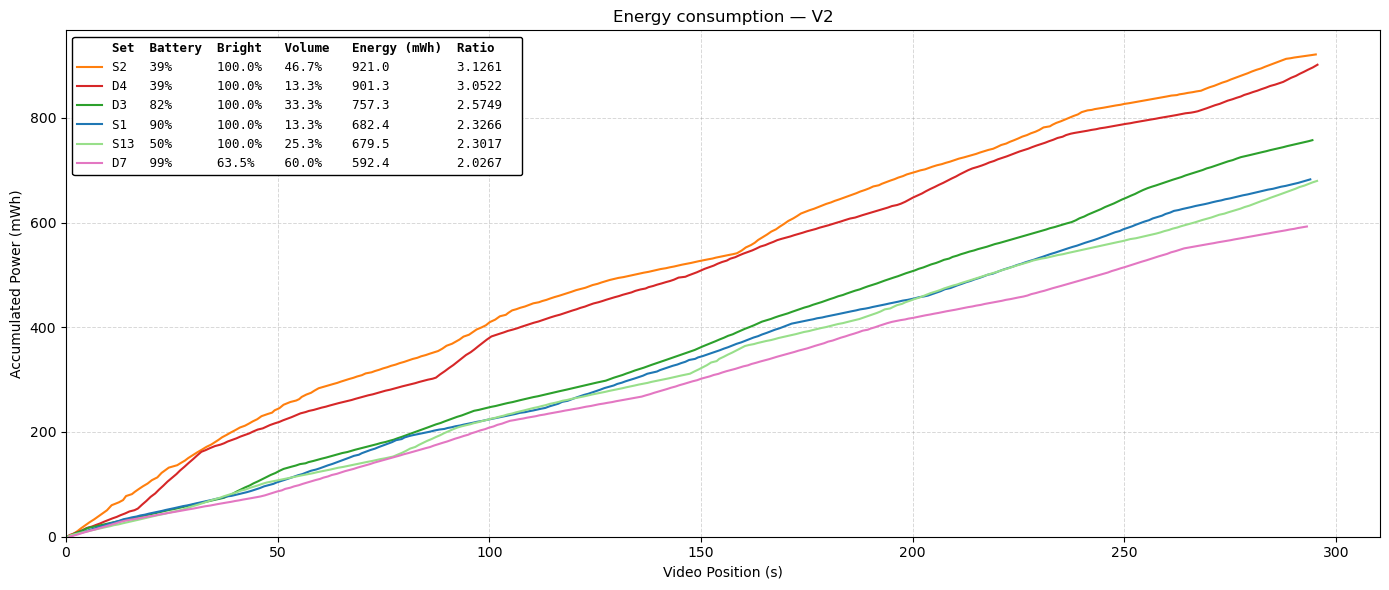

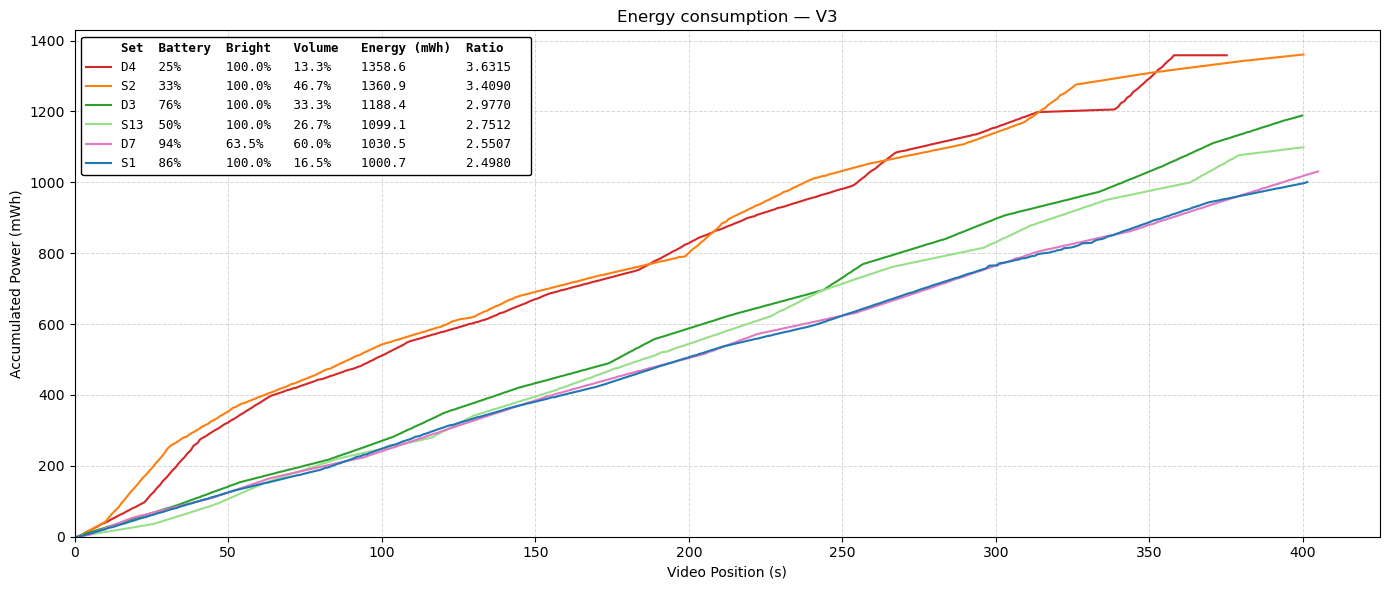

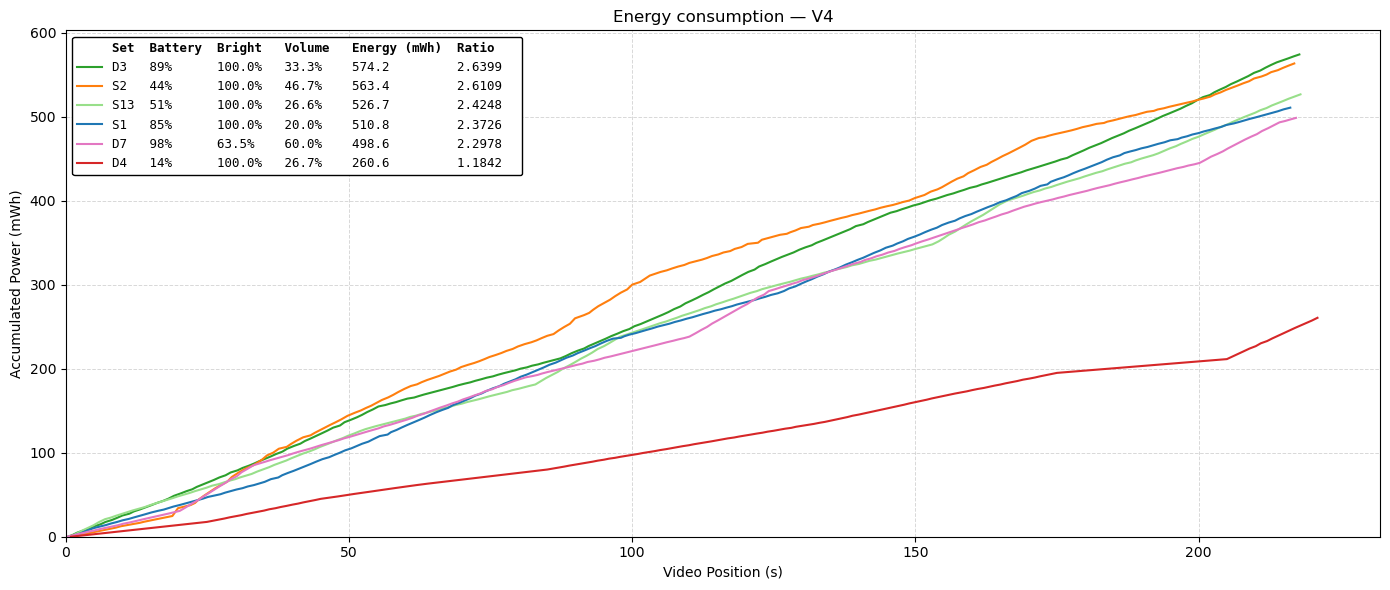

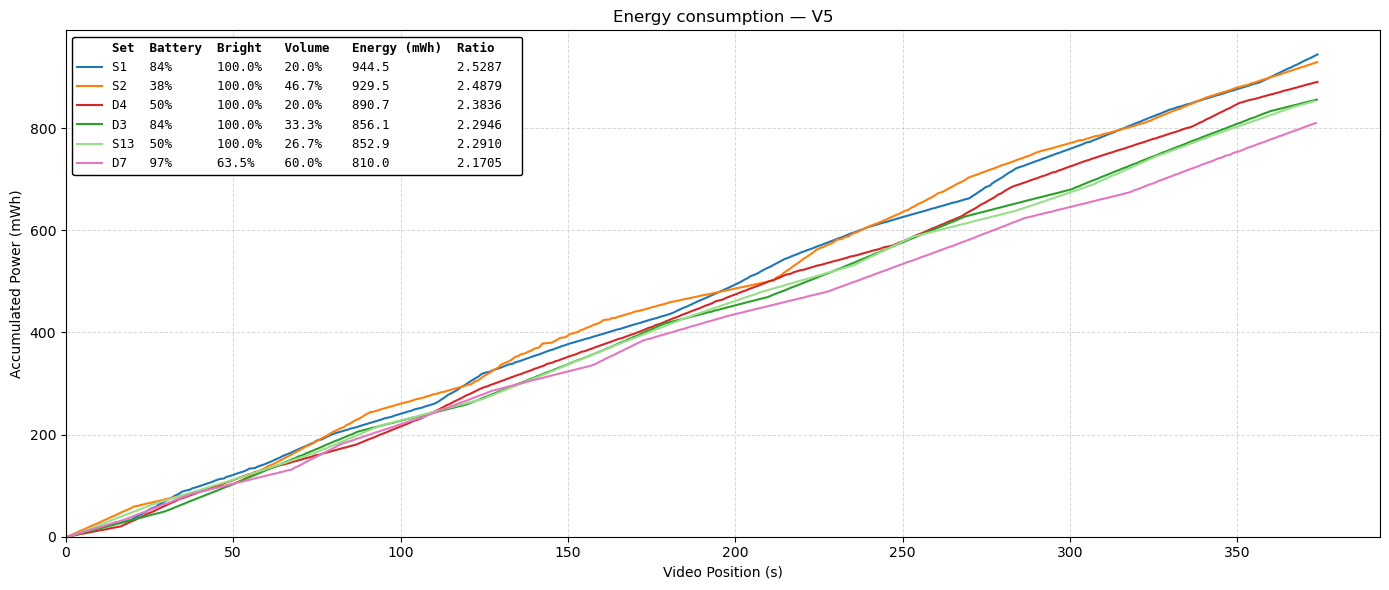

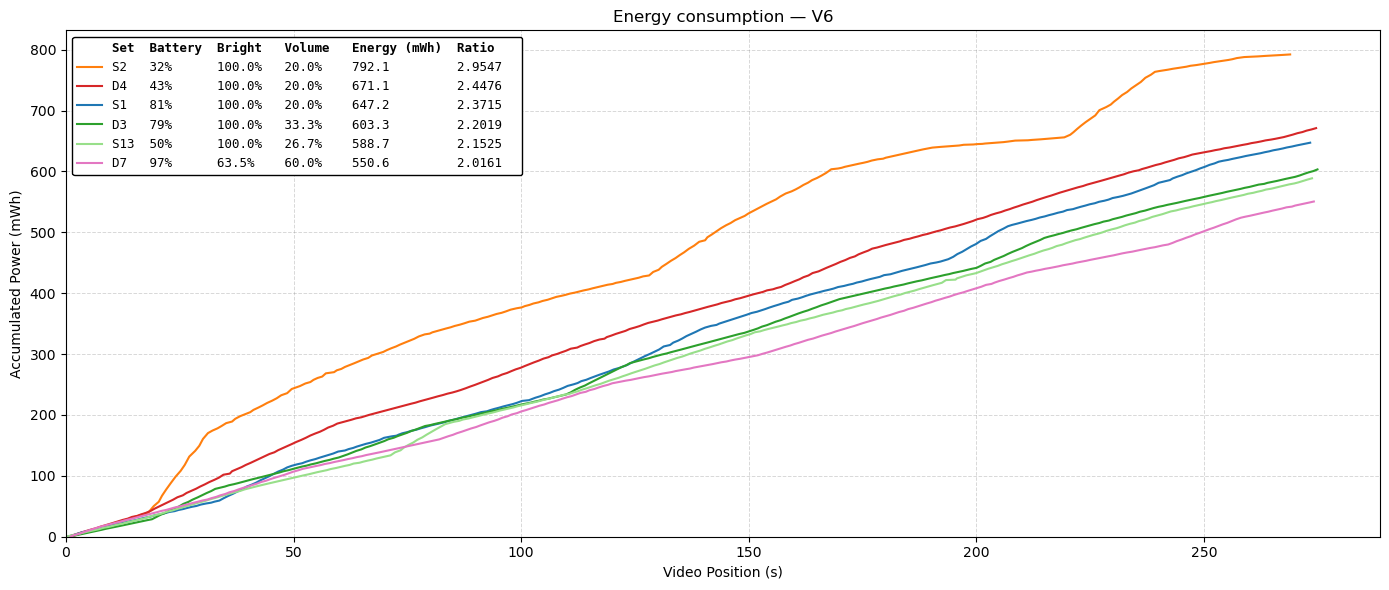

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 5, "battery": 9, "bright": 9, "volume": 9, "energy": 14, "ratio": 8}


def legend_row(set_txt, battery, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{battery:<{COL_W['battery']}}"
            f"{bright:<{COL_W['bright']}}{volume:<{COL_W['volume']}}"
            f"{energy:<{COL_W['energy']}}{ratio:<{COL_W['ratio']}}")


def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))].copy() # Removing specific Sets
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Per-set info for the legend
    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )

    # Ratio: energy per second of video watched (zero length -> NaN)
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Set order by ratio, highest first
    sets = info.sort_values("ratio", ascending=False).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 6))

    for s in sets:
        d = v[v["set_id"] == s]
        r = info.loc[s]
        set_name = STATE_PREFIX.get(r.user_state, "?") + s[1:]   # e.g. S1 -> "S1" (ST), S3 -> "D3" (DY)
        label = legend_row(set_name,
                           f"{r.level_max:.0f}%",
                           f"{r.bright_avg:.1f}%",
                           f"{r.volume_avg:.1f}%",
                           f"{r.energy:.1f}",
                           f"{r.ratio:.4f}")
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=label, color=SET_COLORS[s], linewidth=1.5)

    ax.set_xlabel("Video Position (s)")
    ax.set_ylabel("Accumulated Power (mWh)")
    ax.set_title(f"Energy consumption — {vd}")
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend inside the plot (upper left), in a box, with the header as the first row
    header = legend_row("Set", "Battery", "Bright", "Volume", "Energy (mWh)", "Ratio")
    handles, labels = ax.get_legend_handles_labels()
    header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

    leg = ax.legend([header_handle] + handles, [header] + labels,
                    loc="upper left", frameon=True,
                    facecolor="white", edgecolor="black", framealpha=1,
                    prop={"family": "monospace", "size": 9})
    leg.get_texts()[0].set_fontweight("bold")       # header row in bold

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)

# 2. Consumption for ALL videos (exclusing some Sets) RENAMED:

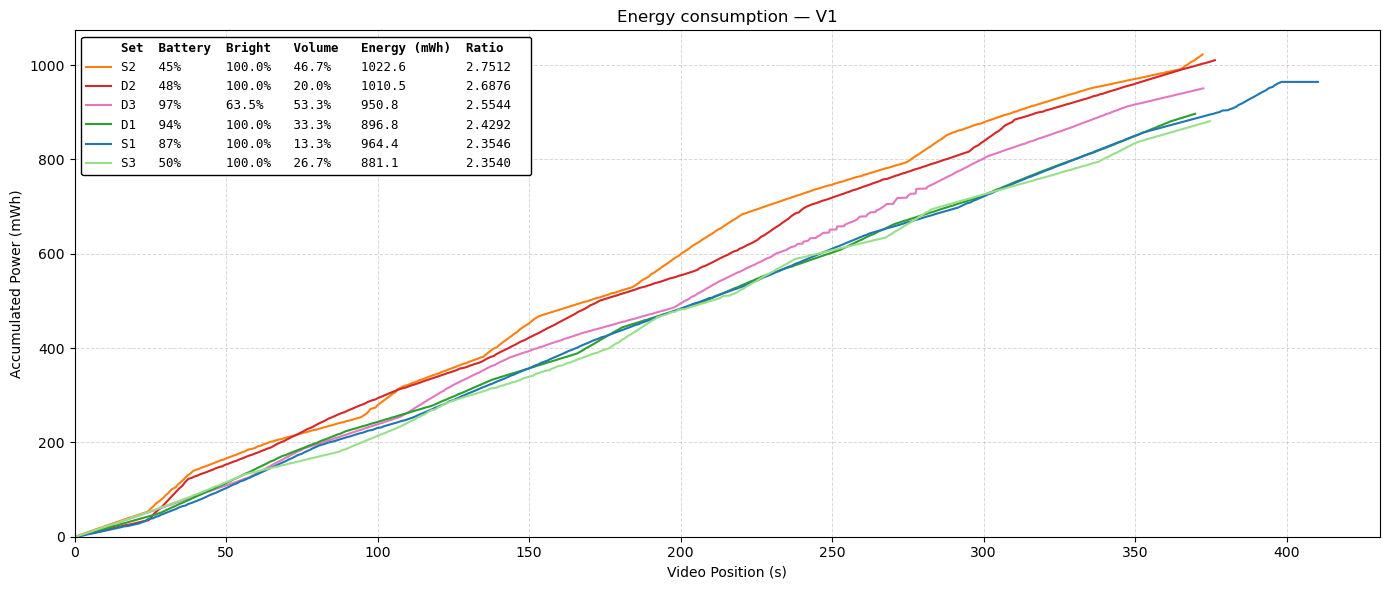

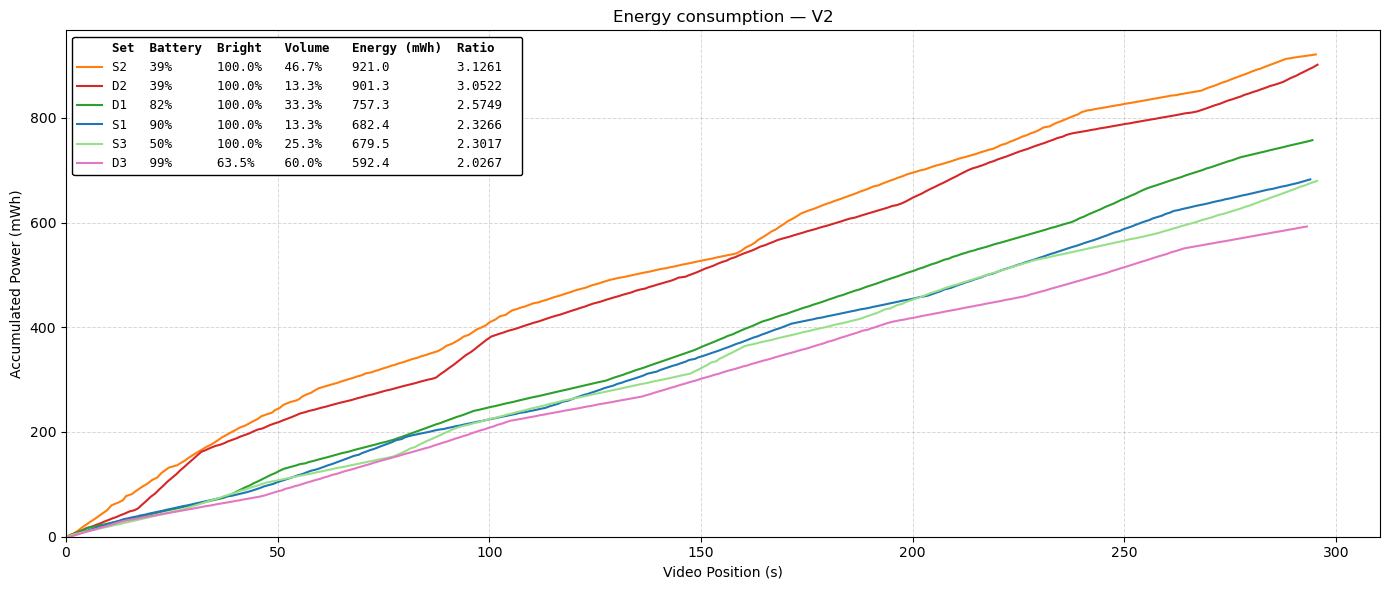

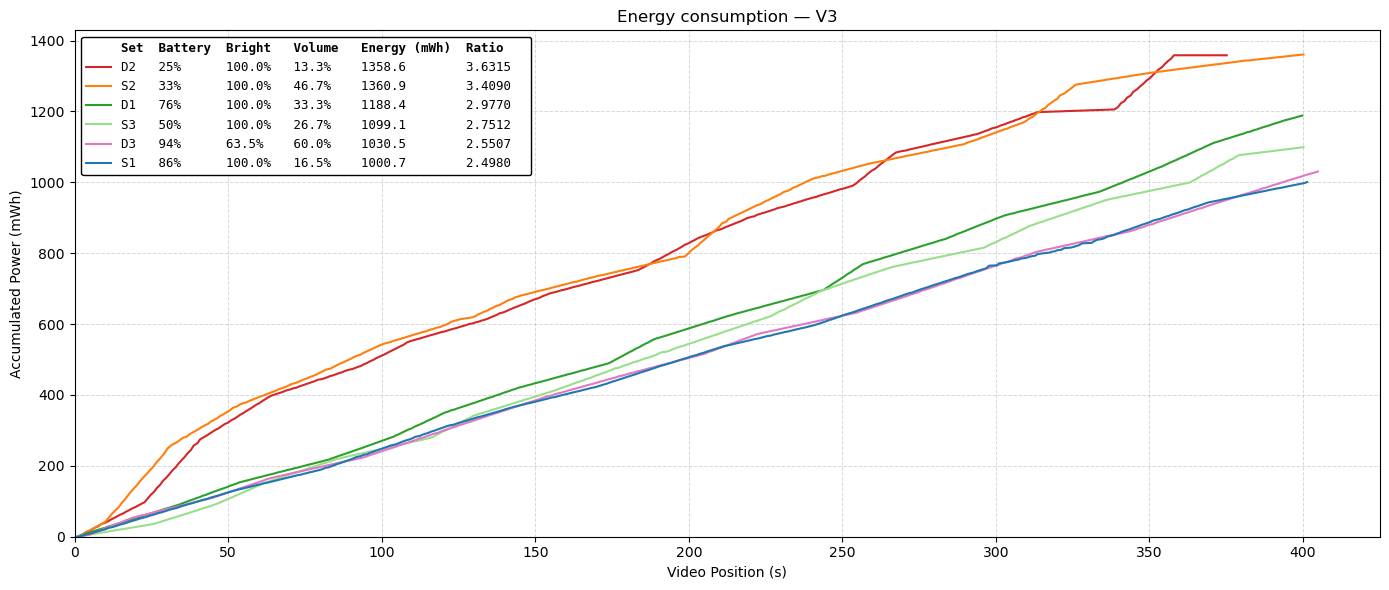

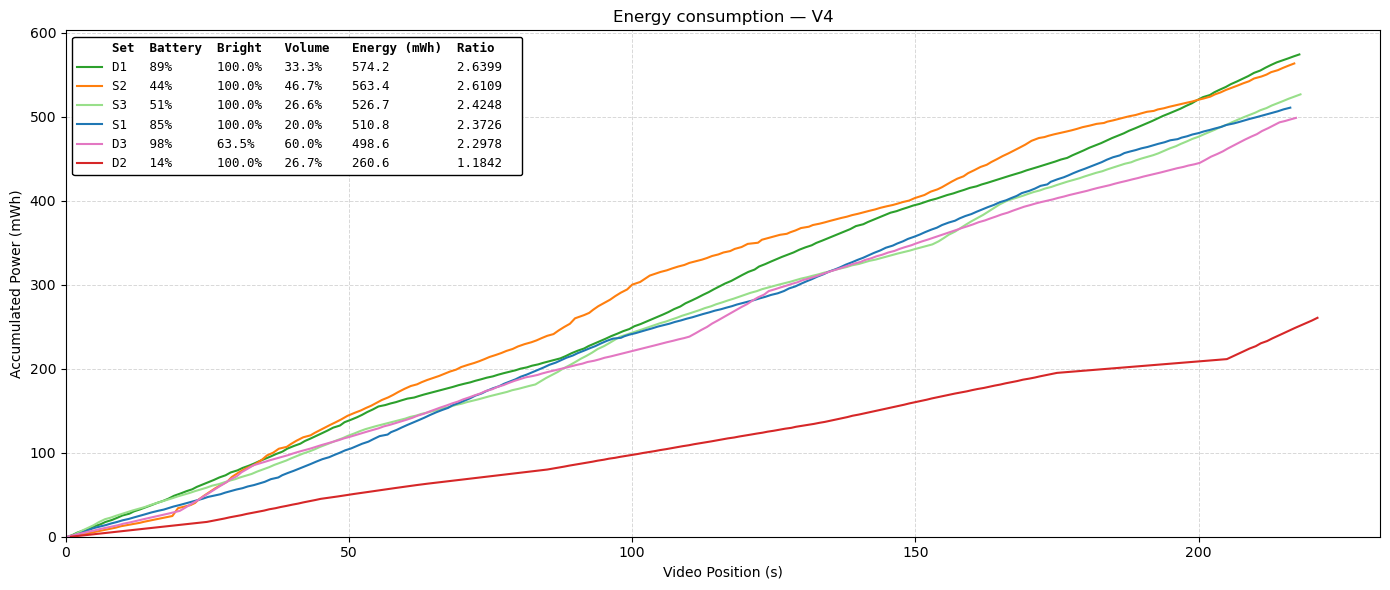

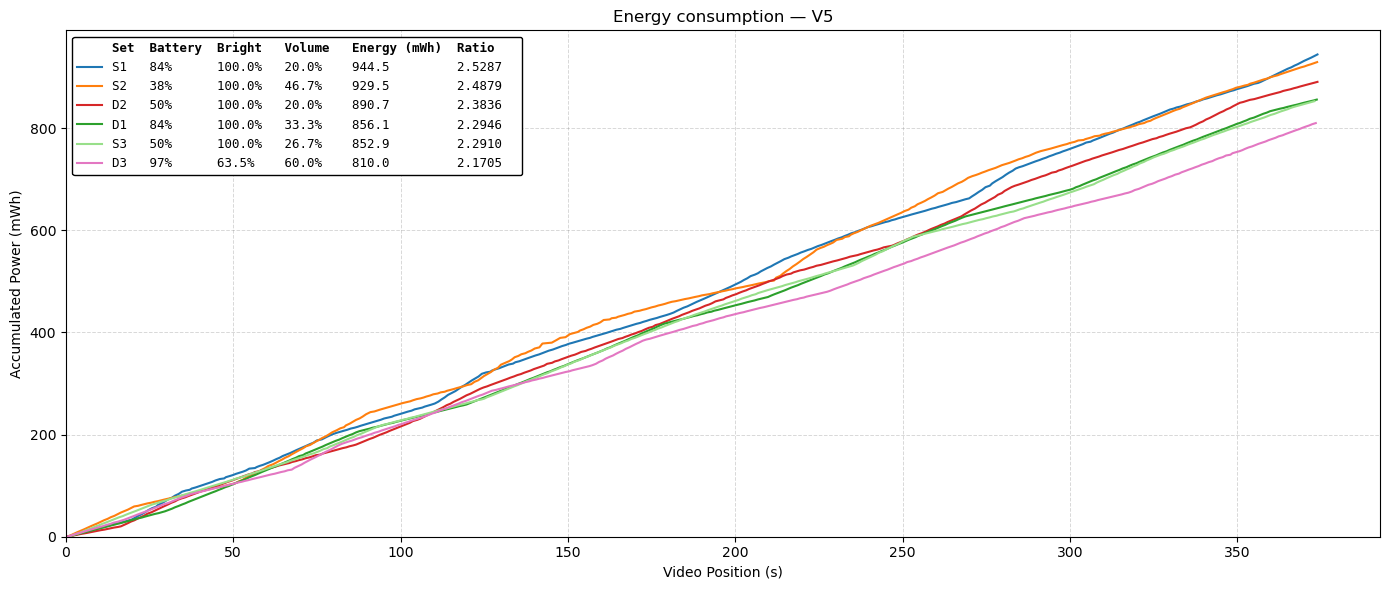

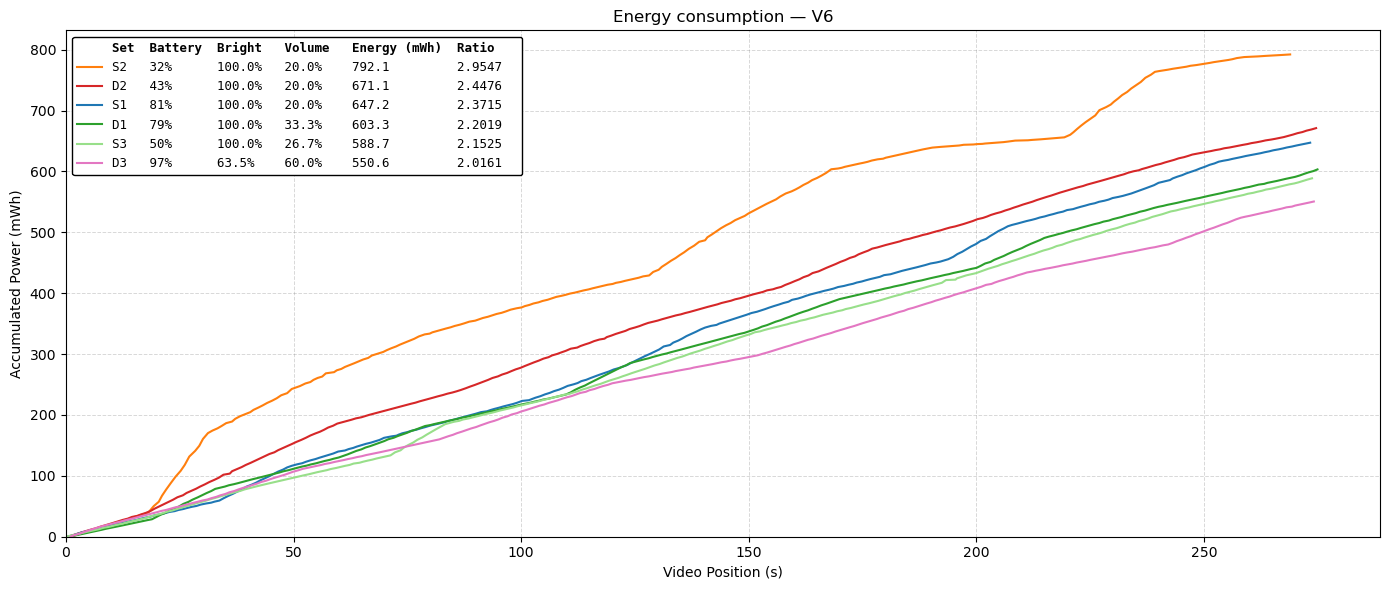

In [33]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names for the legend (S/D name -> new name)
NAME_RENAME = {
    "S1": "S1",
    "S2": "S2",
    "D3": "D1",
    "D4": "D2",
    "D7": "D3",
    "S13": "S3",
}

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 5, "battery": 9, "bright": 9, "volume": 9, "energy": 14, "ratio": 8}


def legend_row(set_txt, battery, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{battery:<{COL_W['battery']}}"
            f"{bright:<{COL_W['bright']}}{volume:<{COL_W['volume']}}"
            f"{energy:<{COL_W['energy']}}{ratio:<{COL_W['ratio']}}")


def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))].copy() # Removing specific Sets
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Per-set info for the legend
    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )

    # Ratio: energy per second of video watched (zero length -> NaN)
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Set order by ratio, highest first
    sets = info.sort_values("ratio", ascending=False).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 6))

    for s in sets:
        d = v[v["set_id"] == s]
        r = info.loc[s]
        set_name = STATE_PREFIX.get(r.user_state, "?") + s[1:]   # e.g. S3 -> "D3" (DY)
        set_name = NAME_RENAME.get(set_name, set_name)          # e.g. "D3" -> "D1"
        label = legend_row(set_name,
                           f"{r.level_max:.0f}%",
                           f"{r.bright_avg:.1f}%",
                           f"{r.volume_avg:.1f}%",
                           f"{r.energy:.1f}",
                           f"{r.ratio:.4f}")
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=label, color=SET_COLORS[s], linewidth=1.5)

    ax.set_xlabel("Video Position (s)")
    ax.set_ylabel("Accumulated Power (mWh)")
    ax.set_title(f"Energy consumption — {vd}")
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend inside the plot (upper left), in a box, with the header as the first row
    header = legend_row("Set", "Battery", "Bright", "Volume", "Energy (mWh)", "Ratio")
    handles, labels = ax.get_legend_handles_labels()
    header_handle = Line2D([], [], color="none")   # invisible line sample, keeps alignment

    leg = ax.legend([header_handle] + handles, [header] + labels,
                    loc="upper left", frameon=True,
                    facecolor="white", edgecolor="black", framealpha=1,
                    prop={"family": "monospace", "size": 9})
    leg.get_texts()[0].set_fontweight("bold")       # header row in bold

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)

# 2. Consumption for ALL videos (exclusing some Sets) RENAMED - Without Legends

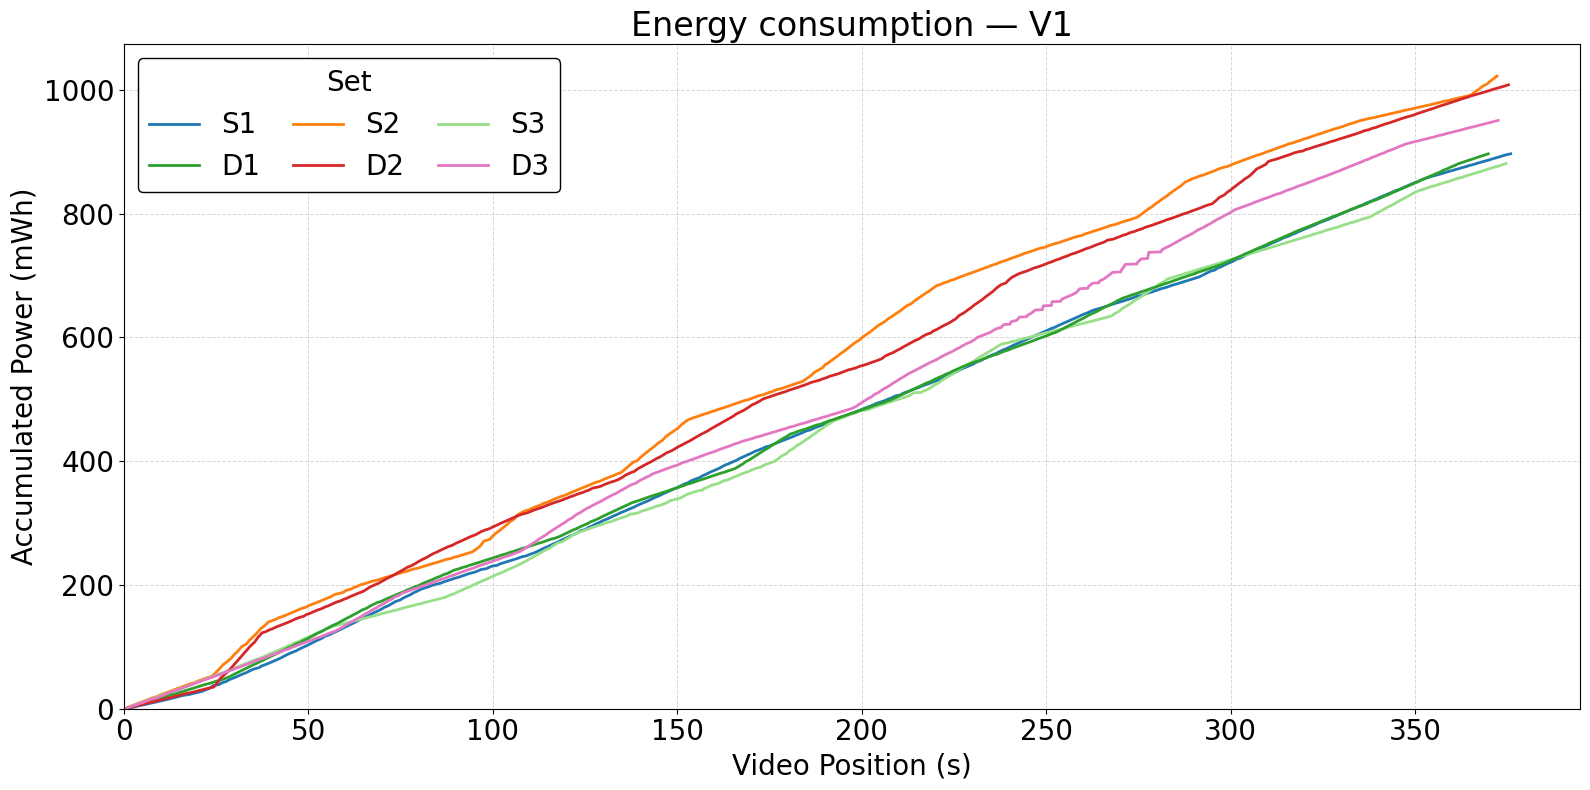

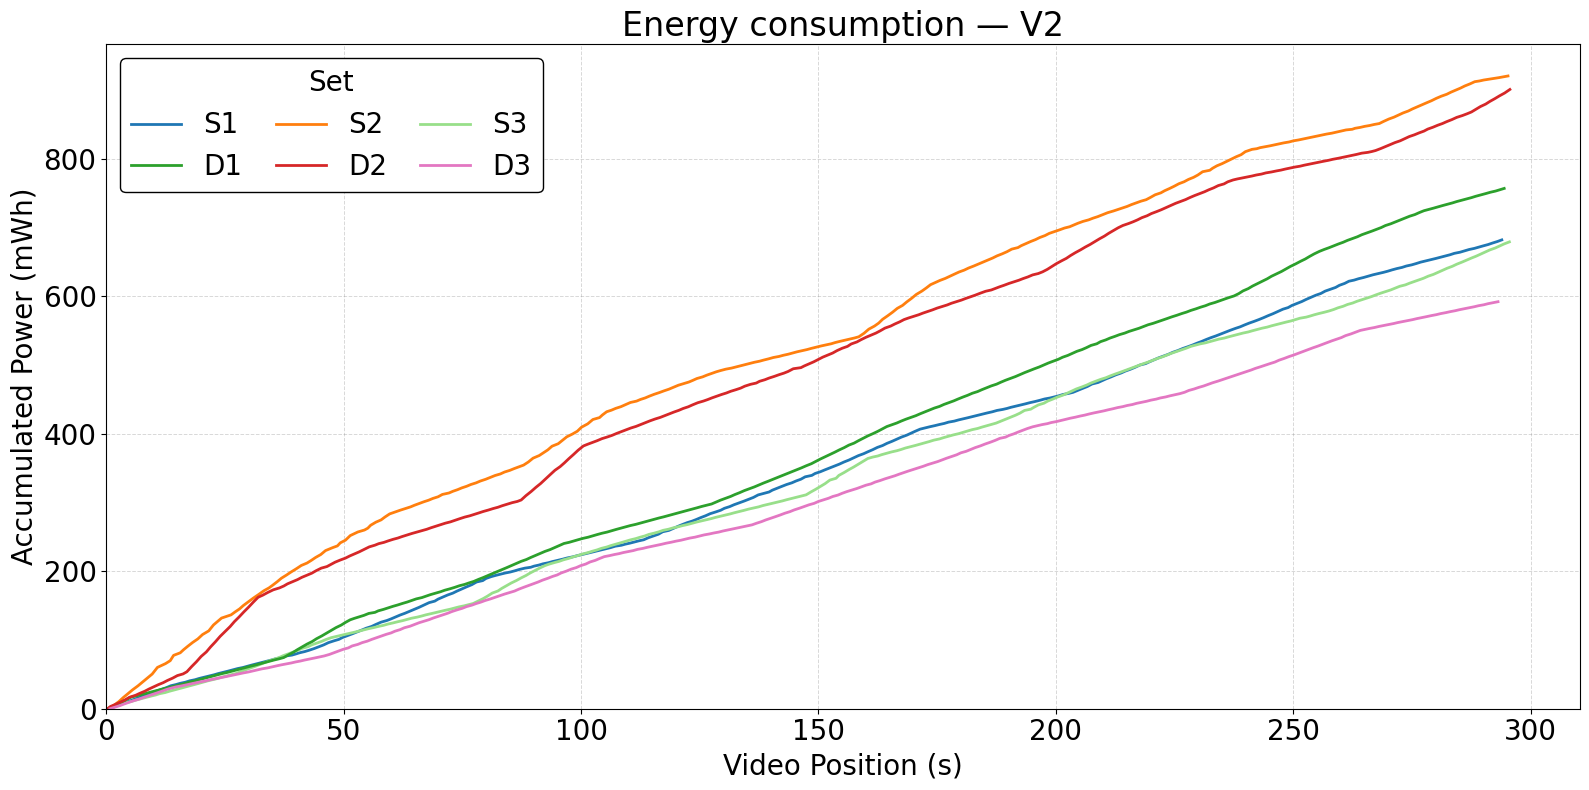

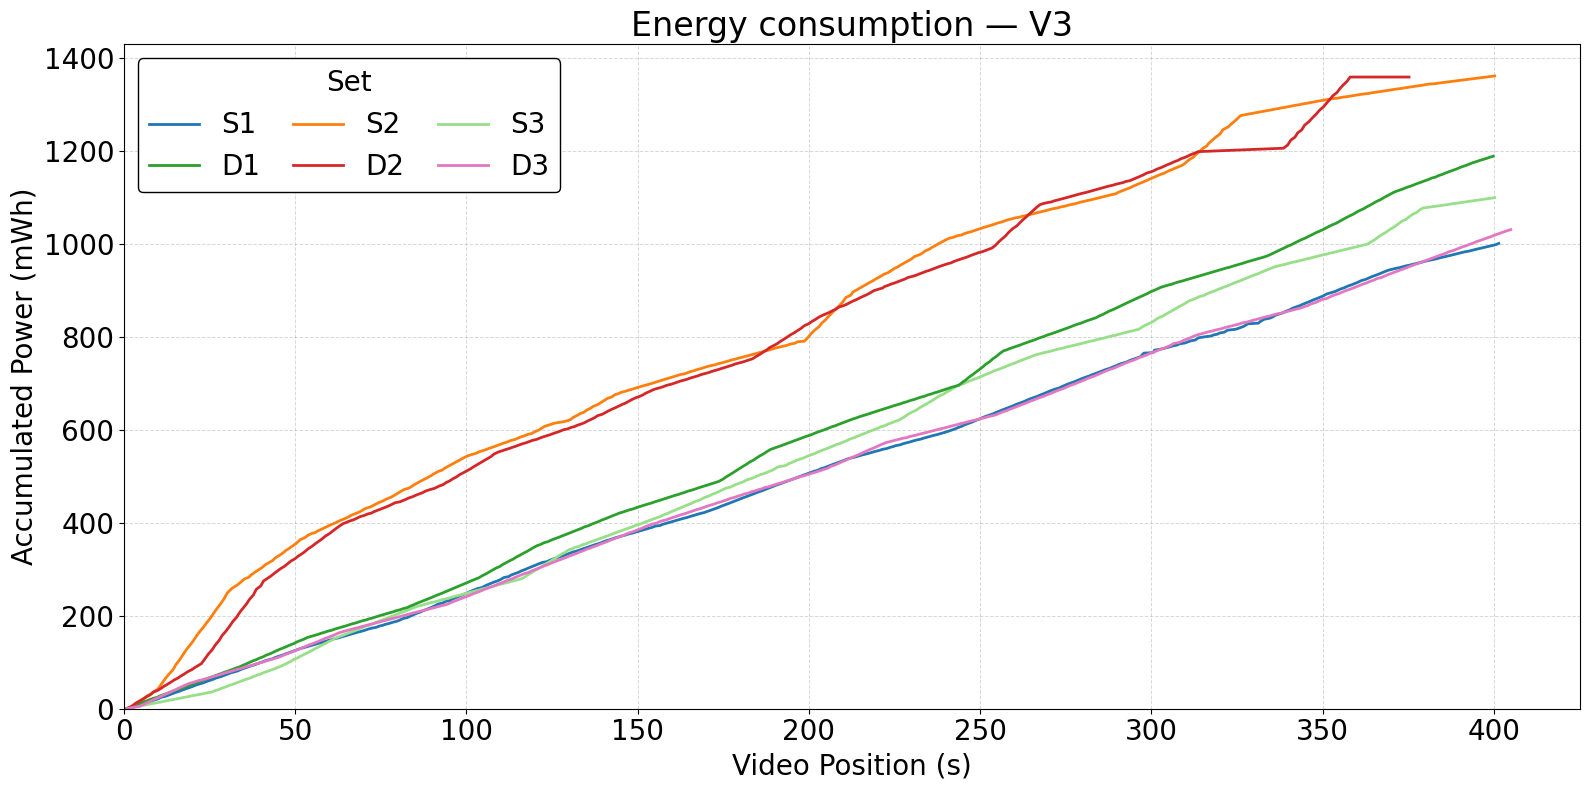

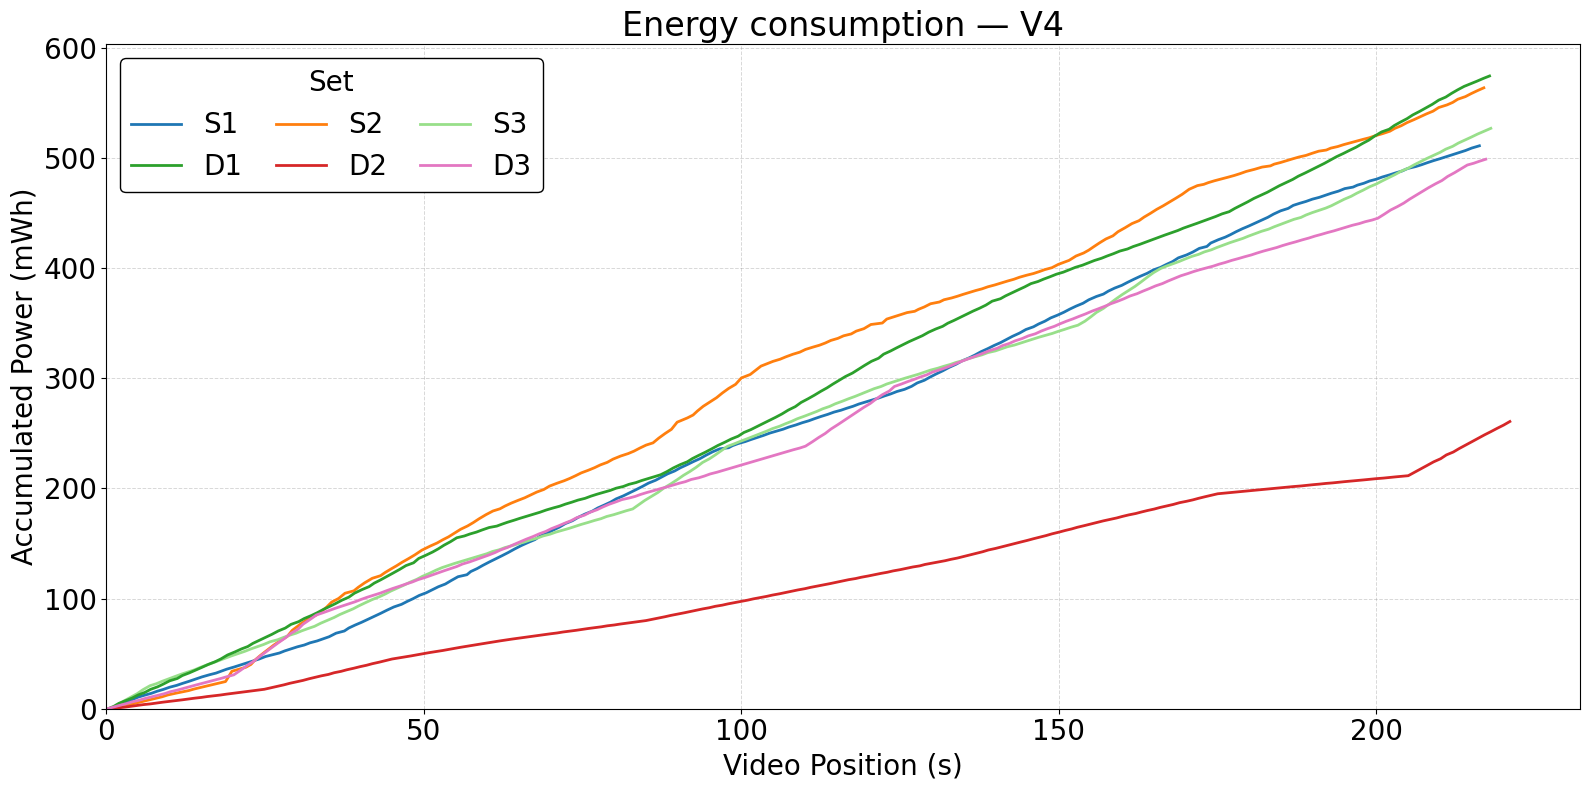

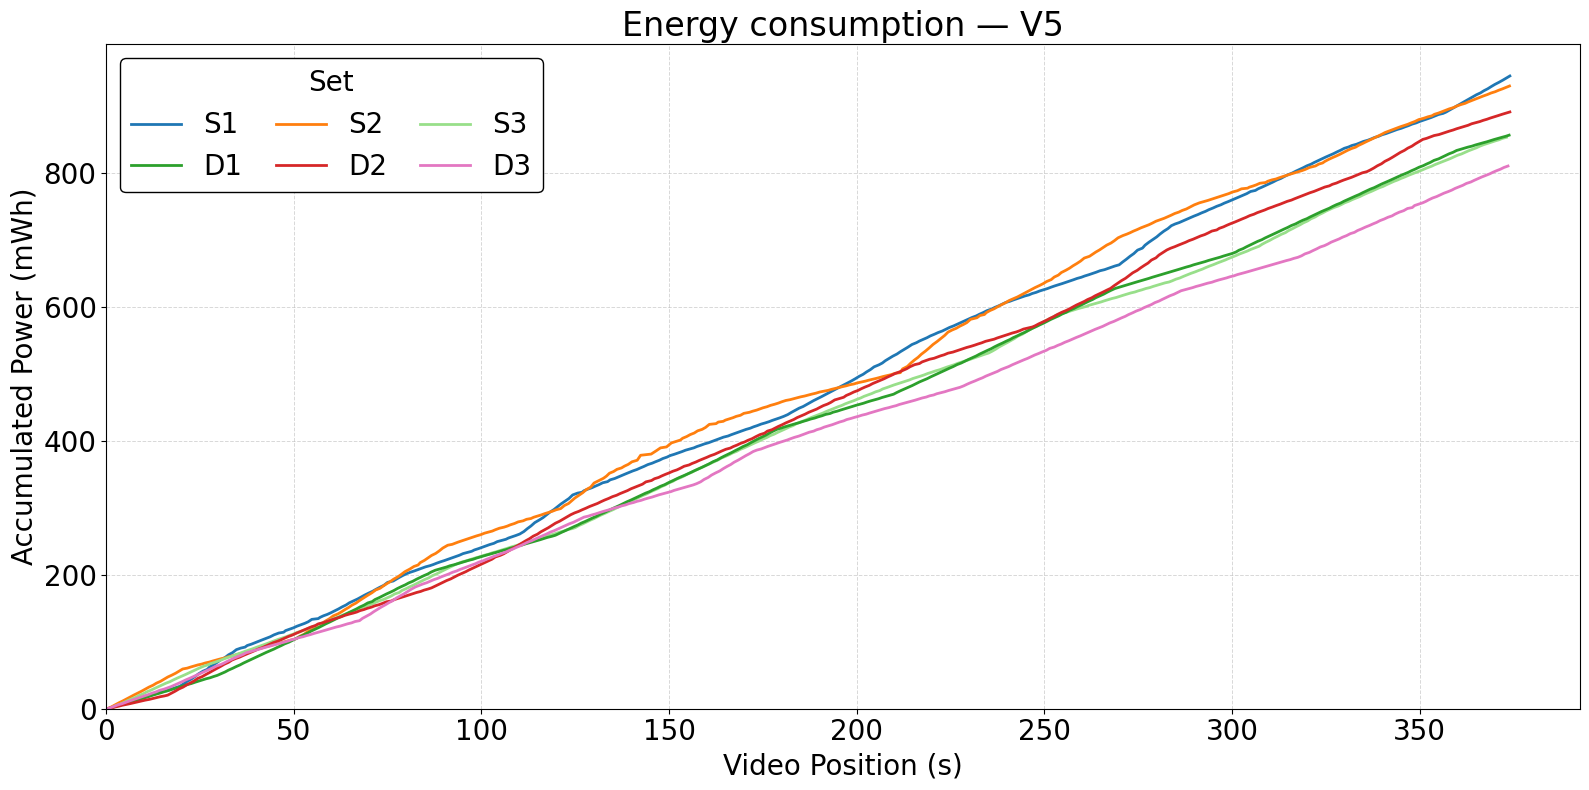

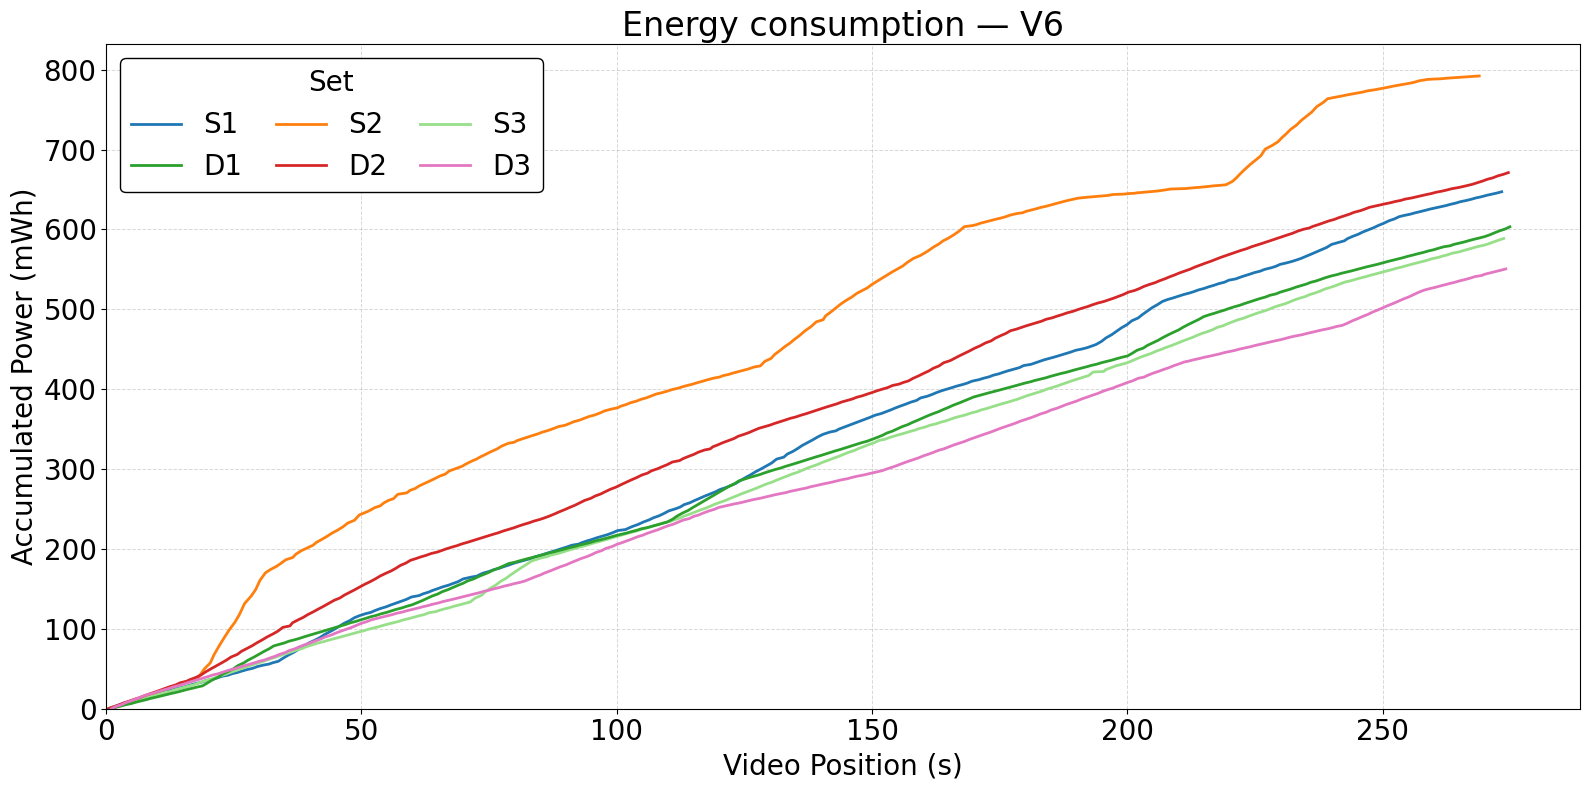

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names for the legend (S/D name -> new name)
NAME_RENAME = {
    "S1": "S1",
    "S2": "S2",
    "D3": "D1",
    "D4": "D2",
    "D7": "D3",
    "S13": "S3",
}

# Manual cutoff per video (seconds); videos not listed are not trimmed
X_CUTOFF = {"V1": 376}

# Font sizes (double the matplotlib defaults)
TITLE_SIZE = 24    # default ~12
LABEL_SIZE = 20    # axis titles, default 10
TICK_SIZE = 20     # numbers on the axes, default 10
LEGEND_SIZE = 20   # legend text and title, default 10


def plot_video(vd):
    """Accumulated power over video position for one video, one line per set."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))].copy() # Removing specific Sets
    if v.empty:
        print(f"No data for {vd}")
        return

    # Shift each set's accumulated power so its first value is 0
    v["Accumulated Power from start (mWh)"] = (
        v["Accumulated Power (mWh)"]
        - v.groupby("set_id")["Accumulated Power (mWh)"].transform("first")
    )

    # Trim lines at the manual cutoff (only for the videos listed in X_CUTOFF)
    if vd in X_CUTOFF:
        v = v[v["Video Position (s)"] <= X_CUTOFF[vd]]

    # Display name per set: S/D prefix + number, then the final renaming
    states = v.groupby("set_id")["user_state"].first()
    names = {}
    for s, st in states.items():
        name = STATE_PREFIX.get(st, "?") + s[1:]   # e.g. S3 -> "D3" (DY)
        names[s] = NAME_RENAME.get(name, name)     # e.g. "D3" -> "D1"

    # Order: S sets first, then D sets, each by number (S1, S2, S3, D1, D2, D3)
    sets = sorted(names, key=lambda s: (names[s][0] != "S", int(names[s][1:])))

    fig, ax = plt.subplots(figsize=(16, 8))   # a bit larger to fit the bigger text

    for s in sets:
        d = v[v["set_id"] == s]
        ax.plot(d["Video Position (s)"], d["Accumulated Power from start (mWh)"],
                label=names[s], color=SET_COLORS[s], linewidth=2)

    ax.set_xlabel("Video Position (s)", fontsize=LABEL_SIZE)
    ax.set_ylabel("Accumulated Power (mWh)", fontsize=LABEL_SIZE)
    ax.set_title(f"Energy consumption — {vd}", fontsize=TITLE_SIZE)
    ax.tick_params(axis="both", which="major", labelsize=TICK_SIZE)
    ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    # Legend in two rows: S sets on top, D sets below
    handles, labels = ax.get_legend_handles_labels()
    s_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("S")]
    d_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("D")]

    ncols = max(len(s_items), len(d_items))
    blank = (Line2D([], [], linestyle="", marker=""), "")   # empty spacer
    s_items += [blank] * (ncols - len(s_items))
    d_items += [blank] * (ncols - len(d_items))

    # Legend fills column by column, so interleave: each column = one S (top) + one D (bottom)
    ordered = [item for pair in zip(s_items, d_items) for item in pair]
    leg_handles, leg_labels = zip(*ordered)

    ax.legend(leg_handles, leg_labels, title="Set", ncol=ncols, loc="upper left",
              frameon=True, facecolor="white", edgecolor="black", framealpha=1,
              fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
              columnspacing=1.2, handlelength=1.8)

    fig.tight_layout()

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed

    fig.savefig(out_dir / f"Energy_consumption_graph_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One graph per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    plot_video(vd)

# 2. Consumption for ALL videos (exclusing some Sets) RENAMED - ONLY TABLES:

Legend — V1


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,S2,45,100.0,46.7,1022.6,2.7512
1,D2,48,100.0,20.0,1010.5,2.6876
2,D3,97,63.5,53.3,950.8,2.5544
3,D1,94,100.0,33.3,896.8,2.4292
4,S1,87,100.0,13.3,964.4,2.3546
5,S3,50,100.0,26.7,881.1,2.3540


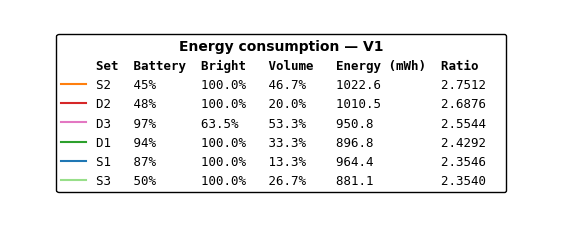

Legend — V2


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,S2,39,100.0,46.7,921.0,3.1261
1,D2,39,100.0,13.3,901.3,3.0522
2,D1,82,100.0,33.3,757.3,2.5749
3,S1,90,100.0,13.3,682.4,2.3266
4,S3,50,100.0,25.3,679.5,2.3017
5,D3,99,63.5,60.0,592.4,2.0267


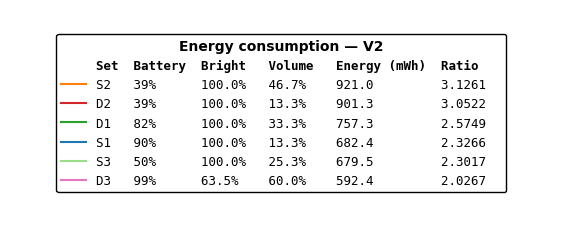

Legend — V3


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,D2,25,100.0,13.3,1358.6,3.6315
1,S2,33,100.0,46.7,1360.9,3.4090
2,D1,76,100.0,33.3,1188.4,2.9770
3,S3,50,100.0,26.7,1099.1,2.7512
4,D3,94,63.5,60.0,1030.5,2.5507
5,S1,86,100.0,16.5,1000.7,2.4980


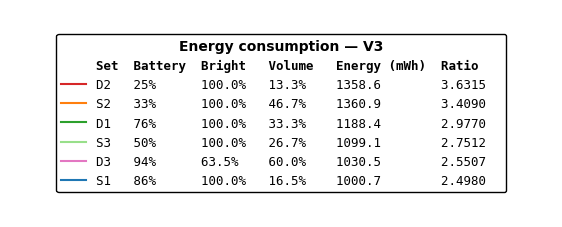

Legend — V4


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,D1,89,100.0,33.3,574.2,2.6399
1,S2,44,100.0,46.7,563.4,2.6109
2,S3,51,100.0,26.6,526.7,2.4248
3,S1,85,100.0,20.0,510.8,2.3726
4,D3,98,63.5,60.0,498.6,2.2978
5,D2,14,100.0,26.7,260.6,1.1842


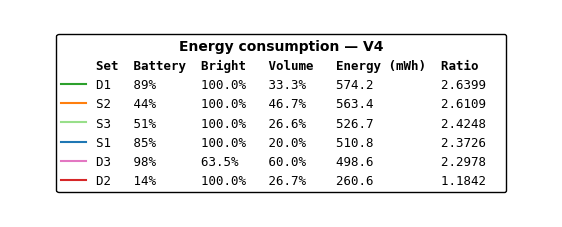

Legend — V5


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,S1,84,100.0,20.0,944.5,2.5287
1,S2,38,100.0,46.7,929.5,2.4879
2,D2,50,100.0,20.0,890.7,2.3836
3,D1,84,100.0,33.3,856.1,2.2946
4,S3,50,100.0,26.7,852.9,2.2910
5,D3,97,63.5,60.0,810.0,2.1705


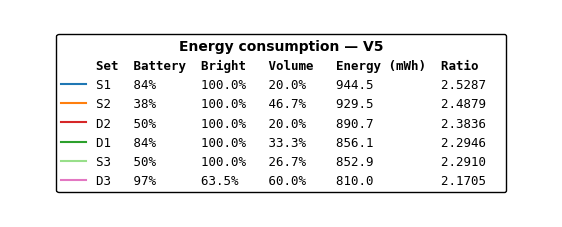

Legend — V6


,Set,Battery (%),Bright (%),Volume (%),Energy (mWh),Ratio
0,S2,32,100.0,20.0,792.1,2.9547
1,D2,43,100.0,20.0,671.1,2.4476
2,S1,81,100.0,20.0,647.2,2.3715
3,D1,79,100.0,33.3,603.3,2.2019
4,S3,50,100.0,26.7,588.7,2.1525
5,D3,97,63.5,60.0,550.6,2.0161


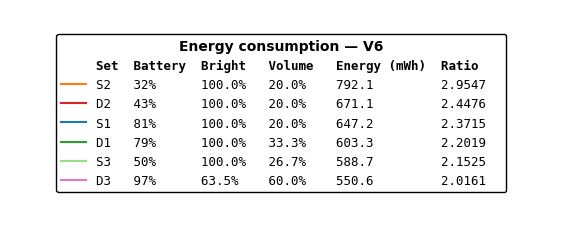

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names for the legend (S/D name -> new name)
NAME_RENAME = {
    "S1": "S1",
    "S2": "S2",
    "D3": "D1",
    "D4": "D2",
    "D7": "D3",
    "S13": "S3",
}

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 5, "battery": 9, "bright": 9, "volume": 9, "energy": 14, "ratio": 8}


def legend_row(set_txt, battery, bright, volume, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{battery:<{COL_W['battery']}}"
            f"{bright:<{COL_W['bright']}}{volume:<{COL_W['volume']}}"
            f"{energy:<{COL_W['energy']}}{ratio:<{COL_W['ratio']}}")


def legend_info(vd):
    """Per-set legend values for one video, ordered by ratio (highest first)."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))]        # Removing specific Sets
    if v.empty:
        return None

    info = v.groupby("set_id").agg(
        level_max=("Level (%)", "max"),
        user_state=("user_state", "first"),
        bright_avg=("Brightness (%)", "mean"),
        volume_avg=("Volume (%)", "mean"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Display name: S/D prefix + number, then the final renaming
    info["set_name"] = [
        NAME_RENAME.get(STATE_PREFIX.get(st, "?") + s[1:], STATE_PREFIX.get(st, "?") + s[1:])
        for s, st in zip(info.index, info["user_state"])
    ]
    return info.sort_values("ratio", ascending=False)


def show_legend(vd):
    """Draw only the legend table for one video (no plot lines)."""
    info = legend_info(vd)
    if info is None:
        print(f"No data for {vd}")
        return

    # 1) As a pandas table
    table = pd.DataFrame({
        "Set": info["set_name"],
        "Battery (%)": info["level_max"].round(0),
        "Bright (%)": info["bright_avg"].round(1),
        "Volume (%)": info["volume_avg"].round(1),
        "Energy (mWh)": info["energy"].round(1),
        "Ratio": info["ratio"].round(4),
    }).reset_index(drop=True)
    print(f"Legend — {vd}")
    display(table)

    # 2) As a figure with only the legend
    handles = [Line2D([], [], color="none")]   # invisible sample for the header row
    labels = [legend_row("Set", "Battery", "Bright", "Volume", "Energy (mWh)", "Ratio")]
    for s, r in info.iterrows():
        handles.append(Line2D([], [], color=SET_COLORS[s], linewidth=1.5))
        labels.append(legend_row(r.set_name,
                                 f"{r.level_max:.0f}%",
                                 f"{r.bright_avg:.1f}%",
                                 f"{r.volume_avg:.1f}%",
                                 f"{r.energy:.1f}",
                                 f"{r.ratio:.4f}"))

    fig, ax = plt.subplots(figsize=(7, 0.3 * len(handles) + 0.6))
    ax.axis("off")   # no axes, ticks or plot area
    leg = ax.legend(handles, labels, loc="center", frameon=True,
                    facecolor="white", edgecolor="black", framealpha=1,
                    title=f"Energy consumption — {vd}",
                    title_fontproperties={"size": 10, "weight": "bold"},
                    prop={"family": "monospace", "size": 9})
    leg.get_texts()[0].set_fontweight("bold")   # header row in bold

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / f"Legend_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One legend per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    show_legend(vd)

# 2. Consumption for ALL videos (exclusing some Sets) RENAMED - ONLY TABLES / v2:

Legend — V1


Set,Energy (mWh),Ratio
S2,1022.6,2.7512
D2,1010.5,2.6876
D3,950.8,2.5544
D1,896.8,2.4292
S1,964.4,2.3546
S3,881.1,2.3540
Total,5726.3,2.5193
Average,954.4,2.5218


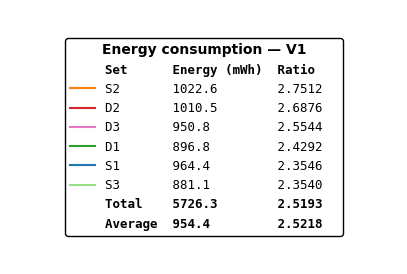

Legend — V2


Set,Energy (mWh),Ratio
S2,921.0,3.1261
D2,901.3,3.0522
D1,757.3,2.5749
S1,682.4,2.3266
S3,679.5,2.3017
D3,592.4,2.0267
Total,4533.8,2.5690
Average,755.6,2.5680


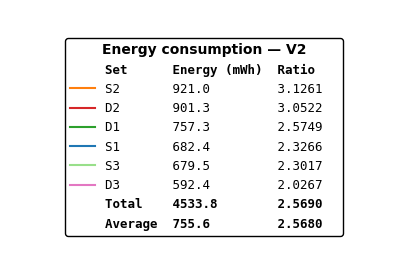

Legend — V3


Set,Energy (mWh),Ratio
D2,1358.6,3.6315
S2,1360.9,3.4090
D1,1188.4,2.9770
S3,1099.1,2.7512
D3,1030.5,2.5507
S1,1000.7,2.4980
Total,7038.1,2.9614
Average,1173.0,2.9696


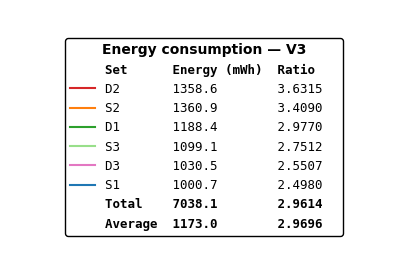

Legend — V4


Set,Energy (mWh),Ratio
D1,574.2,2.6399
S2,563.4,2.6109
S3,526.7,2.4248
S1,510.8,2.3726
D3,498.6,2.2978
D2,260.6,1.1842
Total,2934.3,2.2522
Average,489.1,2.2550


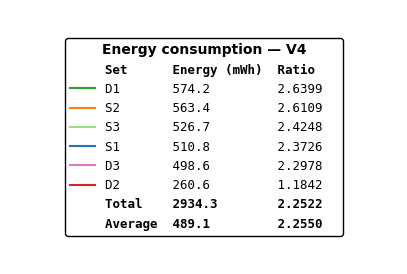

Legend — V5


Set,Energy (mWh),Ratio
S1,944.5,2.5287
S2,929.5,2.4879
D2,890.7,2.3836
D1,856.1,2.2946
S3,852.9,2.2910
D3,810.0,2.1705
Total,5283.8,2.3595
Average,880.6,2.3594


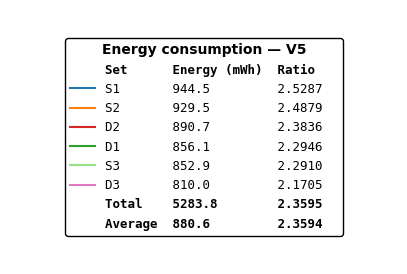

Legend — V6


Set,Energy (mWh),Ratio
S2,792.1,2.9547
D2,671.1,2.4476
S1,647.2,2.3715
D1,603.3,2.2019
S3,588.7,2.1525
D3,550.6,2.0161
Total,3853.1,2.3555
Average,642.2,2.3574


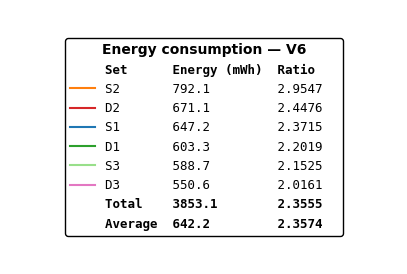

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

# Fixed color per set, the same in every graph
# (strong colors first, so S1–S10 are clearly distinct)
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names for the legend (S/D name -> new name)
NAME_RENAME = {
    "S1": "S1",
    "S2": "S2",
    "D3": "D1",
    "D4": "D2",
    "D7": "D3",
    "S13": "S3",
}

# Legend column widths (characters); header and values share them, all left-aligned
COL_W = {"set": 9, "energy": 14, "ratio": 8}


def legend_row(set_txt, energy, ratio):
    """One legend line with fixed-width, left-aligned columns."""
    return (f"{set_txt:<{COL_W['set']}}{energy:<{COL_W['energy']}}"
            f"{ratio:<{COL_W['ratio']}}")


def legend_info(vd):
    """Per-set legend values for one video, ordered by ratio (highest first)."""
    v = df_all[(df_all["vd_id"] == vd)
               & (df_all["user_state"] != "SQ")                   # Removing Sequences
               & (~df_all["set_id"].isin(["S10", "S11"]))]        # Removing specific Sets
    if v.empty:
        return None

    info = v.groupby("set_id").agg(
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    info["ratio"] = info["energy"] / info["video_length"].replace(0, np.nan)

    # Display name: S/D prefix + number, then the final renaming
    info["set_name"] = [
        NAME_RENAME.get(STATE_PREFIX.get(st, "?") + s[1:], STATE_PREFIX.get(st, "?") + s[1:])
        for s, st in zip(info.index, info["user_state"])
    ]
    return info.sort_values("ratio", ascending=False)


def show_legend(vd):
    """Draw only the legend table for one video (no plot lines)."""
    info = legend_info(vd)
    if info is None:
        print(f"No data for {vd}")
        return

    # Summary values
    total_energy = info["energy"].sum()
    total_ratio = total_energy / info["video_length"].sum()   # overall energy per second
    avg_energy = info["energy"].mean()
    avg_ratio = info["ratio"].mean()

    # 1) As a pandas table, with Total and Average rows in bold
    table = pd.DataFrame({
        "Set": info["set_name"],
        "Energy (mWh)": info["energy"].round(1),
        "Ratio": info["ratio"].round(4),
    }).reset_index(drop=True)
    summary = pd.DataFrame({
        "Set": ["Total", "Average"],
        "Energy (mWh)": [round(total_energy, 1), round(avg_energy, 1)],
        "Ratio": [round(total_ratio, 4), round(avg_ratio, 4)],
    })
    table = pd.concat([table, summary], ignore_index=True)

    n_sets = len(info)
    styled = (table.style
              .apply(lambda row: ["font-weight: bold" if row.name >= n_sets else ""] * len(row),
                     axis=1)
              .format({"Energy (mWh)": "{:.1f}", "Ratio": "{:.4f}"})
              .hide(axis="index"))
    print(f"Legend — {vd}")
    display(styled)

    # 2) As a figure with only the legend
    handles = [Line2D([], [], color="none")]   # invisible sample for the header row
    labels = [legend_row("Set", "Energy (mWh)", "Ratio")]
    for s, r in info.iterrows():
        handles.append(Line2D([], [], color=SET_COLORS[s], linewidth=1.5))
        labels.append(legend_row(r.set_name, f"{r.energy:.1f}", f"{r.ratio:.4f}"))

    # Total and Average rows (no line sample)
    handles += [Line2D([], [], color="none"), Line2D([], [], color="none")]
    labels += [legend_row("Total", f"{total_energy:.1f}", f"{total_ratio:.4f}"),
               legend_row("Average", f"{avg_energy:.1f}", f"{avg_ratio:.4f}")]

    fig, ax = plt.subplots(figsize=(5, 0.3 * len(handles) + 0.6))
    ax.axis("off")   # no axes, ticks or plot area
    leg = ax.legend(handles, labels, loc="center", frameon=True,
                    facecolor="white", edgecolor="black", framealpha=1,
                    title=f"Energy consumption — {vd}",
                    title_fontproperties={"size": 10, "weight": "bold"},
                    prop={"family": "monospace", "size": 9})

    # Bold: header row and the last two rows (Total, Average)
    texts = leg.get_texts()
    for t in [texts[0], texts[-2], texts[-1]]:
        t.set_fontweight("bold")

    out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / f"Legend_{vd}.pdf", dpi=300, bbox_inches="tight")

    plt.show()


# One legend per video, V1 to V6
videos = sorted(df_all["vd_id"].unique(), key=lambda v: int(v[1:]))
for vd in videos:
    show_legend(vd)

# 2. SCATTER PLOTS:

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

# Fixed color per set, the same in every graph
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

EXCLUDE_SETS = ["S10", "S11"]

v = df_all[(df_all["user_state"] != "SQ")
           & (~df_all["set_id"].isin(EXCLUDE_SETS))]

# One row per (video, set) with initial SOC and ratio
summary = (
    v.groupby(["vd_id", "set_id"])
    .agg(
        level_max=("Level (%)", "max"),
        volume_avg=("Volume (%)", "mean"),
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    .reset_index()
)
summary["ratio"] = summary["energy"] / summary["video_length"].replace(0, np.nan)
summary["set_name"] = summary["user_state"].map(STATE_PREFIX).fillna("?") + summary["set_id"].str[1:]

### 2.1. SCATTER FOR {S1, S2, S13, D3, D4, D7}:

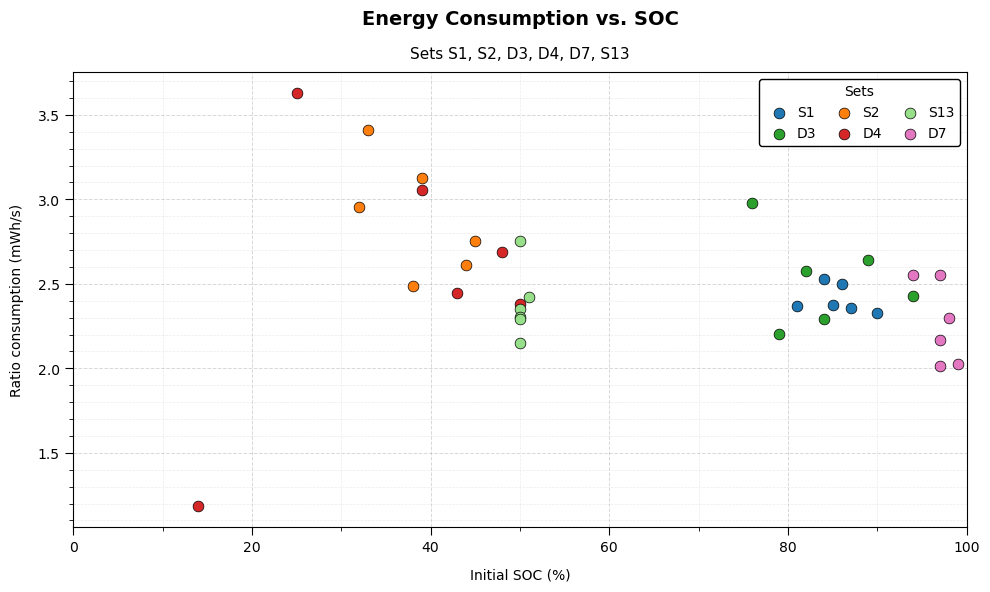

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

# Sets in numeric order (S1, S2, ..., S13) so the legend is sorted
set_order = sorted(summary["set_id"].unique(), key=lambda s: int(s[1:]))

for s in set_order:
    g = summary[summary["set_id"] == s]
    ax.scatter(g["level_max"], g["ratio"], color=SET_COLORS[s], marker="o",
               s=60, edgecolor="black", linewidth=0.5, label=g["set_name"].iloc[0])


ax.set_xlabel("Initial SOC (%)", labelpad=10)
ax.set_ylabel("Ratio consumption (mWh/s)", labelpad=10)
ax.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bold title, with the list of sets as a subtitle below it
set_list = sorted(summary["set_name"].unique(), key=lambda s: int(s[1:]))
title = fig.suptitle("Energy Consumption vs. SOC", fontsize=14, fontweight="bold")
ax.set_title(f"Sets {', '.join(set_list)}", fontsize=11, color="black", pad=10)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)


# ax.legend(title="Set", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
# Legend in two rows: S sets on top, D sets below
handles, labels = ax.get_legend_handles_labels()
s_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("S")]
d_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("D")]

ncols = max(len(s_items), len(d_items))
blank = (Line2D([], [], linestyle="", marker=""), "")   # empty spacer
s_items += [blank] * (ncols - len(s_items))
d_items += [blank] * (ncols - len(d_items))

# Interleave so each column holds one S (top) and one D (bottom)
ordered = [item for pair in zip(s_items, d_items) for item in pair]
leg_handles, leg_labels = zip(*ordered)

ax.legend(leg_handles, leg_labels, title="Sets", ncol=ncols, loc="best",
          frameon=True, facecolor="white", edgecolor="black", framealpha=1,
          columnspacing=1.0, handletextpad=0.3)

fig.tight_layout()

# Center the main title over the plot area (same center as the subtitle)
pos = ax.get_position()
title.set_x(pos.x0 + pos.width / 2)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_set.pdf", dpi=300, bbox_inches="tight")

plt.show()

### 2.1. SCATTER FOR {S1, S2, S13, D3, D4, D7} RENAMED AS {S1, S2, S3, D1, D2, D3}

### 2.2. SCATTER FOR DYNAMIC (D) & STATIC (S):

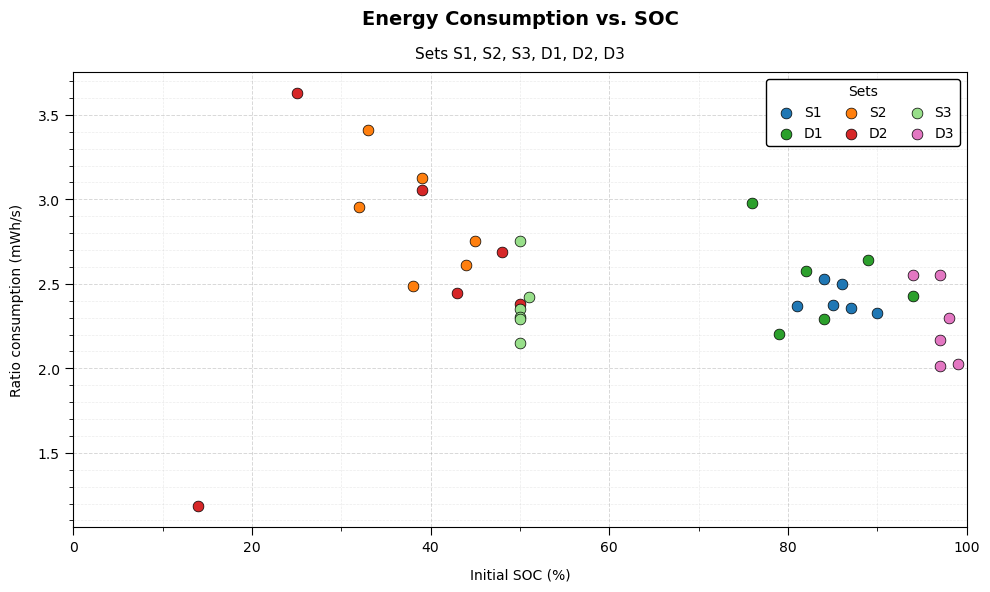

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

# ---------- Setup: colors, names and summary table ----------

# Fixed color per set, the same in every graph
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2", "D7": "D3", "S13": "S3"}

EXCLUDE_SETS = ["S10", "S11"]

v = df_all[(df_all["user_state"] != "SQ")
           & (~df_all["set_id"].isin(EXCLUDE_SETS))]

# One row per (video, set) with initial SOC and ratio
summary = (
    v.groupby(["vd_id", "set_id"])
    .agg(
        level_max=("Level (%)", "max"),
        volume_avg=("Volume (%)", "mean"),
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    .reset_index()
)
summary["ratio"] = summary["energy"] / summary["video_length"].replace(0, np.nan)
summary["set_name"] = summary["user_state"].map(STATE_PREFIX).fillna("?") + summary["set_id"].str[1:]
summary["set_name"] = summary["set_name"].replace(NAME_RENAME)   # e.g. D3 -> D1, S13 -> S3

# ---------- Plot ----------

fig, ax = plt.subplots(figsize=(10, 6))

# Sets ordered by their new names (S1, S2, S3 ... / D1, D2, D3 ...) so the legend is sorted
name_by_set = summary.drop_duplicates("set_id").set_index("set_id")["set_name"]
set_order = sorted(name_by_set.index, key=lambda s: int(name_by_set[s][1:]))

for s in set_order:
    g = summary[summary["set_id"] == s]
    ax.scatter(g["level_max"], g["ratio"], color=SET_COLORS[s], marker="o",
               s=60, edgecolor="black", linewidth=0.5, label=g["set_name"].iloc[0],
               zorder=3, clip_on=False)

ax.set_xlabel("Initial SOC (%)", labelpad=10)
ax.set_ylabel("Ratio consumption (mWh/s)", labelpad=10)

# Bold title, with the list of sets as a subtitle below it
set_list = sorted(summary["set_name"].unique(), key=lambda s: (s[0] != "S", int(s[1:])))
title = fig.suptitle("Energy Consumption vs. SOC", fontsize=14, fontweight="bold")
ax.set_title(f"Sets {', '.join(set_list)}", fontsize=11, color="black", pad=10)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend in two rows: S sets on top, D sets below
handles, labels = ax.get_legend_handles_labels()
s_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("S")]
d_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("D")]

ncols = max(len(s_items), len(d_items))
blank = (Line2D([], [], linestyle="", marker=""), "")   # empty spacer
s_items += [blank] * (ncols - len(s_items))
d_items += [blank] * (ncols - len(d_items))

# Interleave so each column holds one S (top) and one D (bottom)
ordered = [item for pair in zip(s_items, d_items) for item in pair]
leg_handles, leg_labels = zip(*ordered)

ax.legend(leg_handles, leg_labels, title="Sets", ncol=ncols, loc="best",
          frameon=True, facecolor="white", edgecolor="black", framealpha=1,
          columnspacing=1.0, handletextpad=0.3)

fig.tight_layout()

# Center the main title over the plot area (same center as the subtitle)
pos = ax.get_position()
title.set_x(pos.x0 + pos.width / 2)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_set.pdf", dpi=300, bbox_inches="tight")

plt.show()

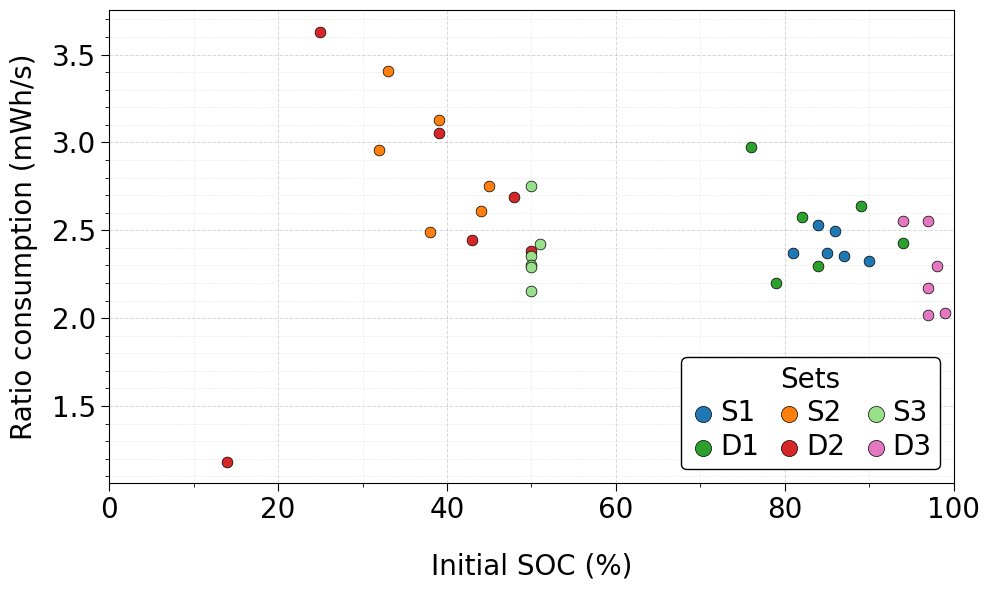

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

# ---------- Setup: colors, names and summary table ----------

# Fixed color per set, the same in every graph
palette = plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]
all_sets = sorted(df_all["set_id"].unique(), key=lambda s: int(s[1:]))
SET_COLORS = {s: palette[i % len(palette)] for i, s in enumerate(all_sets)}

# Legend prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2", "D7": "D3", "S13": "S3"}

EXCLUDE_SETS = ["S10", "S11"]

v = df_all[(df_all["user_state"] != "SQ")
           & (~df_all["set_id"].isin(EXCLUDE_SETS))]

# One row per (video, set) with initial SOC and ratio
summary = (
    v.groupby(["vd_id", "set_id"])
    .agg(
        level_max=("Level (%)", "max"),
        volume_avg=("Volume (%)", "mean"),
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    .reset_index()
)
summary["ratio"] = summary["energy"] / summary["video_length"].replace(0, np.nan)
summary["set_name"] = summary["user_state"].map(STATE_PREFIX).fillna("?") + summary["set_id"].str[1:]
summary["set_name"] = summary["set_name"].replace(NAME_RENAME)   # e.g. D3 -> D1, S13 -> S3

# ---------- Plot ----------

FONT_SIZE = 20   # axis titles, tick numbers and legend (default is 10)

fig, ax = plt.subplots(figsize=(10, 6))

# Sets ordered by their new names (S1, S2, S3 ... / D1, D2, D3 ...) so the legend is sorted
name_by_set = summary.drop_duplicates("set_id").set_index("set_id")["set_name"]
set_order = sorted(name_by_set.index, key=lambda s: int(name_by_set[s][1:]))

for s in set_order:
    g = summary[summary["set_id"] == s]
    ax.scatter(g["level_max"], g["ratio"], color=SET_COLORS[s], marker="o",
               s=60, edgecolor="black", linewidth=0.5, label=g["set_name"].iloc[0],
               zorder=3, clip_on=False)

ax.set_xlabel("Initial SOC (%)", labelpad=20, fontsize=FONT_SIZE)
ax.set_ylabel("Ratio consumption (mWh/s)", labelpad=10, fontsize=FONT_SIZE)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6, labelsize=FONT_SIZE)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend in two rows: S sets on top, D sets below
handles, labels = ax.get_legend_handles_labels()
s_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("S")]
d_items = [(h, l) for h, l in zip(handles, labels) if l.startswith("D")]

ncols = max(len(s_items), len(d_items))
blank = (Line2D([], [], linestyle="", marker=""), "")   # empty spacer
s_items += [blank] * (ncols - len(s_items))
d_items += [blank] * (ncols - len(d_items))

# Interleave so each column holds one S (top) and one D (bottom)
ordered = [item for pair in zip(s_items, d_items) for item in pair]
leg_handles, leg_labels = zip(*ordered)

ax.legend(leg_handles, leg_labels, title="Sets", ncol=ncols, loc="lower right",
          frameon=True, facecolor="white", edgecolor="black", framealpha=1,
          fontsize=FONT_SIZE, title_fontsize=FONT_SIZE, markerscale=1.5,
          columnspacing=0.6,   # space between columns
          handletextpad=0.1,   # space between dot and label
          handlelength=1.0,    # width reserved for the marker
          labelspacing=0.2,    # vertical space between rows
          borderpad=0.3)       # padding inside the frame
fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_set.pdf", dpi=300, bbox_inches="tight")

plt.show()

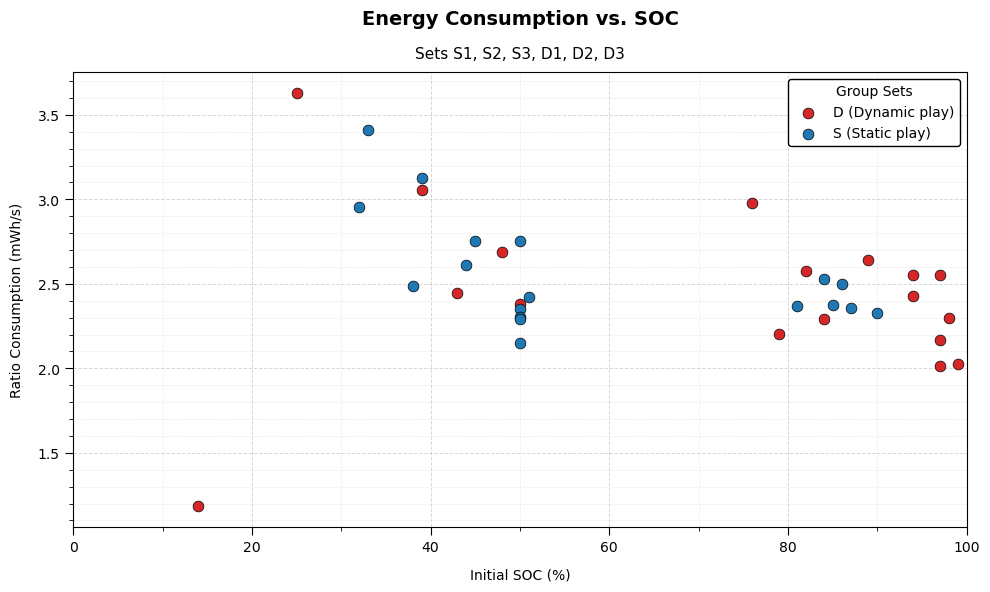

In [48]:
from matplotlib.ticker import MultipleLocator

# One color per group: S = ST sets, D = DY sets
GROUP_COLORS = {"S": "tab:blue", "D": "tab:red"}
GROUP_LABELS = {"S": "S (Static play)", "D": "D (Dynamic play)"}

fig, ax = plt.subplots(figsize=(10, 6))

for prefix, g in summary.groupby(summary["set_name"].str[0]):
    ax.scatter(g["level_max"], g["ratio"], color=GROUP_COLORS.get(prefix, "gray"),
               marker="o", s=60, edgecolor="black", linewidth=0.5,
               label=GROUP_LABELS.get(prefix, prefix), zorder=3, clip_on=False)

# Axis labels a bit further from their axes
ax.set_xlabel("Initial SOC (%)", labelpad=10)
ax.set_ylabel("Ratio Consumption (mWh/s)", labelpad=10)

# Bold title, with the list of sets as a subtitle below it
set_list = sorted(summary["set_name"].unique(), key=lambda s: int(s[1:]))
title = fig.suptitle("Energy Consumption vs. SOC", fontsize=14, fontweight="bold")
ax.set_title("Sets S1, S2, S3, D1, D2, D3", fontsize=11, color="black", pad=10)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend in a box, inside the plot, placed where it overlaps the fewest points
ax.legend(title="Group Sets", loc="best", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1)

fig.tight_layout()

# Center the main title over the plot area (same center as the subtitle)
pos = ax.get_position()
title.set_x(pos.x0 + pos.width / 2)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_state.pdf", dpi=300, bbox_inches="tight")

plt.show()

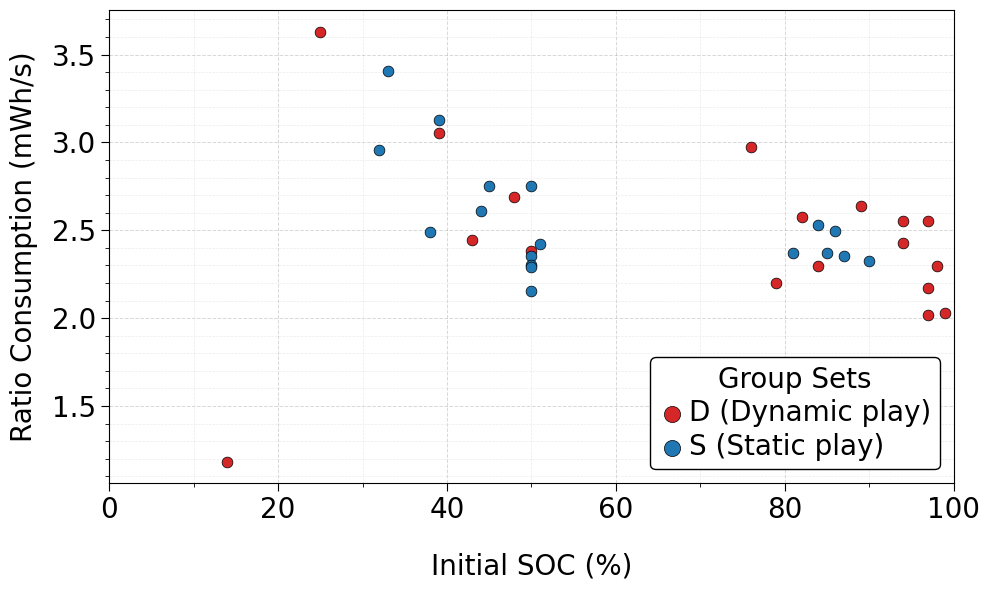

In [49]:
from matplotlib.ticker import MultipleLocator

# One color per group: S = ST sets, D = DY sets
GROUP_COLORS = {"S": "tab:blue", "D": "tab:red"}
GROUP_LABELS = {"S": "S (Static play)", "D": "D (Dynamic play)"}

FONT_SIZE = 20   # axis titles, tick numbers and legend (default is 10)

fig, ax = plt.subplots(figsize=(10, 6))

for prefix, g in summary.groupby(summary["set_name"].str[0]):
    ax.scatter(g["level_max"], g["ratio"], color=GROUP_COLORS.get(prefix, "gray"),
               marker="o", s=60, edgecolor="black", linewidth=0.5,
               label=GROUP_LABELS.get(prefix, prefix), zorder=3, clip_on=False)

# Axis labels a bit further from their axes
ax.set_xlabel("Initial SOC (%)", labelpad=20, fontsize=FONT_SIZE)
ax.set_ylabel("Ratio Consumption (mWh/s)", labelpad=10, fontsize=FONT_SIZE)

# X-axis from 0 to 100, numbered every 20, unnumbered ticks every 10
ax.set_xlim(0, 100)
ax.xaxis.set_major_locator(MultipleLocator(20))   # numbered ticks: 0, 20, 40, 60, 80, 100
ax.xaxis.set_minor_locator(MultipleLocator(10))   # unnumbered ticks: 10, 30, 50, 70, 90

# Y-axis: unnumbered ticks every 0.1
ax.yaxis.set_minor_locator(MultipleLocator(0.1))  # unnumbered ticks: 1.6, 1.7, ...

ax.tick_params(which="minor", length=3)
ax.tick_params(which="major", length=6, labelsize=FONT_SIZE)

# Grid: main lines, plus lighter lines at the intermediate ticks
ax.set_axisbelow(True)
ax.grid(True, which="major", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)
ax.grid(True, which="minor", color="gray", alpha=0.15, linestyle="--", linewidth=0.5)

# Legend in a box, bottom right, compact spacing
ax.legend(title="Group Sets", loc="lower right", frameon=True,
          facecolor="white", edgecolor="black", framealpha=1,
          fontsize=FONT_SIZE, title_fontsize=FONT_SIZE, markerscale=1.5,
          handletextpad=0.1,   # space between dot and label
          handlelength=1.0,    # width reserved for the marker
          labelspacing=0.2,    # vertical space between rows
          borderpad=0.3)       # padding inside the frame

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "Ratio_vs_battery_scatter_by_state.pdf", dpi=300, bbox_inches="tight")

plt.show()

### 3. LAST GRAPH:

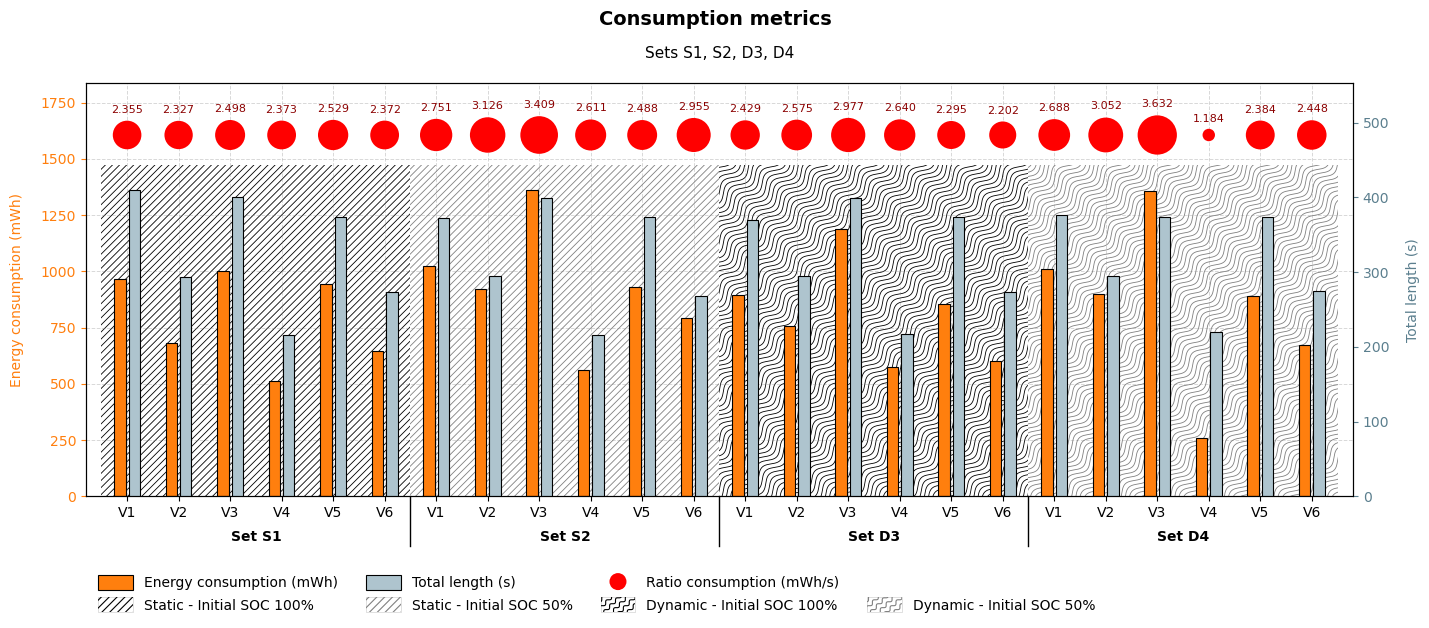

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# Sets to include on the x-axis (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Colors
CONS_COLOR = "tab:orange"        # energy consumption bars
LENGTH_COLOR = "#AEC4CE"         # total length bars (light blue-grey)
LENGTH_TEXT_COLOR = "#5B7F8E"    # darker blue-grey for the right axis text (readable)
BAR_EDGE = dict(edgecolor="black", linewidth=0.8)   # thin black outline on bars

# Background pattern per set (by display name): (line color, curved?)
BG_PATTERNS = {
    "S1": ("black", False),   # straight diagonal, black
    "S2": ("gray",  False),   # straight diagonal, gray
    "D3": ("black", True),    # curved diagonal, black
    "D4": ("gray",  True),    # curved diagonal, gray
}

# Legend text for each background style: (line color, curved?, label)
PATTERN_LEGEND = [
    ("black", False, "Static - Initial SOC 100%"),
    ("gray",  False, "Static - Initial SOC 50%"),
    ("black", True,  "Dynamic - Initial SOC 100%"),
    ("gray",  True,  "Dynamic - Initial SOC 50%"),
]


def diagonal_lines(x0, y0, x1, y1, curved, spacing, amplitude, wavelength, n=600):
    """Points for 45° diagonal lines (straight or wavy) covering the box (x0, y0)-(x1, y1)."""
    d = np.array([1, 1]) / np.sqrt(2)    # direction along the lines
    p = np.array([-1, 1]) / np.sqrt(2)   # direction between lines
    corners = np.array([[x0, y0], [x1, y0], [x0, y1], [x1, y1]])
    c_min, c_max = (corners @ p).min(), (corners @ p).max()
    t_min, t_max = (corners @ d).min(), (corners @ d).max()
    t = np.linspace(t_min, t_max, n)
    wave = amplitude * np.sin(2 * np.pi * t / wavelength) if curved else np.zeros_like(t)
    for c in np.arange(c_min, c_max + spacing, spacing):
        yield np.outer(t, d) + np.outer(c + wave, p)


def diagonal_background(ax, x0, x1, color, curved=False, y_top=1.0,
                        spacing=0.05, amplitude=0.04, wavelength=0.35, lw=0.6):
    """Diagonal lines behind the bars between x0 and x1, from the bottom of the plot
    up to y_top (fraction of the axes height). spacing, amplitude, wavelength in inches."""
    fig = ax.figure
    pos = ax.get_position()
    W = pos.width * fig.get_figwidth()     # axes width in inches
    H = pos.height * fig.get_figheight()   # axes height in inches
    xlo, xhi = ax.get_xlim()
    fx0, fx1 = (x0 - xlo) / (xhi - xlo), (x1 - xlo) / (xhi - xlo)

    clip = Rectangle((fx0, 0), fx1 - fx0, y_top, transform=ax.transAxes)
    for pts in diagonal_lines(fx0 * W, 0, fx1 * W, y_top * H, curved,
                              spacing, amplitude, wavelength):
        line, = ax.plot(pts[:, 0] / W, pts[:, 1] / H, transform=ax.transAxes,
                        color=color, linewidth=lw, zorder=0.2)
        line.set_clip_path(clip)


class DiagonalHandler(HandlerBase):
    """Legend swatch showing the diagonal pattern (straight or curved)."""
    def __init__(self, color, curved):
        super().__init__()
        self.color, self.curved = color, curved

    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        x0, y0 = -xdescent, -ydescent
        box = Rectangle((x0, y0), width, height, facecolor="white",
                        edgecolor="lightgray", linewidth=0.5, transform=trans)
        clip = Rectangle((x0, y0), width, height, transform=trans)
        artists = [box]
        for pts in diagonal_lines(x0, y0, x0 + width, y0 + height, self.curved,
                                  spacing=4, amplitude=1.0, wavelength=6, n=100):
            ln = Line2D(pts[:, 0], pts[:, 1], color=self.color, linewidth=0.8,
                        transform=trans)
            ln.set_clip_path(clip)
            artists.append(ln)
        return artists


subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and rate
bar_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        **{
            "user_state": ("user_state", "first"),
            "total_consumption (mWh)": ("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
            "total_length (s)": ("Video Position (s)", lambda p: p.max() - p.min()),
        }
    )
    .reset_index()
)
bar_df["consumption_rate (mWh/s)"] = (
    bar_df["total_consumption (mWh)"] / bar_df["total_length (s)"].replace(0, np.nan)
)

# Order: by set number, then video number
bar_df = bar_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names: S + number for Static sets, D + number for Dynamic sets
bar_df["set_name"] = bar_df["user_state"].map(STATE_PREFIX).fillna("?") + bar_df["set_id"].str[1:]

x = np.arange(len(bar_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue-grey bars
offset = width / 2 + gap / 2

cons = bar_df["total_consumption (mWh)"]
length = bar_df["total_length (s)"]
ratio = bar_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(max(12, len(x) * 0.6), 6.5))   # wider for more bars
ax2 = ax1.twinx()   # second y-axis on the right

# Gray grid behind the bars
ax1.set_axisbelow(True)
ax1.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bars with a thin black outline
bars1 = ax1.bar(x - offset, cons, width, color=CONS_COLOR, **BAR_EDGE,
                label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width, color=LENGTH_COLOR, **BAR_EDGE,
                label="Total length (s)")

# Leave free space at the top of both axes for the circles
headroom = 1.35
ax1.set_ylim(0, cons.max() * headroom)
ax2.set_ylim(0, length.max() * headroom)

# Circle size scaled linearly with the ratio (smallest -> min_size, largest -> max_size)
min_size, max_size = 80, 800
r_min, r_max = ratio.min(), ratio.max()
if r_max > r_min:
    sizes = min_size + (ratio - r_min) / (r_max - r_min) * (max_size - min_size)
else:
    sizes = np.full(len(ratio), (min_size + max_size) / 2)

# Solid red circles, no outline
circle_y = cons.max() * 1.18
circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3,
                      label="Ratio consumption (mWh/s)")

# Ratio value horizontal, centered, just above each circle (regular weight)
for xi, r, sz in zip(x, ratio, sizes):
    radius_pt = np.sqrt(sz / np.pi)   # circle radius in points
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, radius_pt + 3),
                 textcoords="offset points", ha="center", va="bottom",
                 fontsize=8, fontweight="normal", color="darkred")

# Same small margin on both sides of the bars
side_margin = 0.8
ax1.set_xlim(-side_margin, len(x) - 1 + side_margin)

# Axes labels, colored to match their bars, a bit further from the axes
ax1.set_ylabel("Energy consumption (mWh)", color=CONS_COLOR, labelpad=12)
ax2.set_ylabel("Total length (s)", color=LENGTH_TEXT_COLOR, labelpad=12)
ax1.tick_params(axis="y", colors=CONS_COLOR)
ax2.tick_params(axis="y", colors=LENGTH_TEXT_COLOR)

# Tick labels V1..V6, with "Set S1", "Set S2", ... centered below each group
ax1.set_xticks(x)
ax1.set_xticklabels(bar_df["vd_id"])
groups = list(bar_df.groupby("set_name", sort=False))
for name, g in groups:
    ax1.text(g.index.to_numpy().mean(), -0.08, f"Set {name}",
             transform=ax1.get_xaxis_transform(), ha="center", va="top",
             fontsize=10, fontweight="bold")

# Short separator lines below the x-axis between sets
for _, g in groups[:-1]:
    sep_x = g.index.max() + 0.5
    ax1.plot([sep_x, sep_x], [0, -0.12], transform=ax1.get_xaxis_transform(),
             color="black", linewidth=1, clip_on=False)

# Legend: metrics on the first row, background patterns on the second
pattern_handles = [Patch(label=label) for _, _, label in PATTERN_LEGEND]
handler_map = {h: DiagonalHandler(color, curved)
               for h, (color, curved, _) in zip(pattern_handles, PATTERN_LEGEND)}
blank = Patch(visible=False, label="")

# Legend fills column by column, so interleave to get two clean rows
handles = [bars1, pattern_handles[0],
           bars2, pattern_handles[1],
           circles, pattern_handles[2],
           blank, pattern_handles[3]]
leg = ax1.legend(handles=handles, handler_map=handler_map,
                 loc="upper left", bbox_to_anchor=(0, -0.16), ncol=4,
                 frameon=False, handlelength=2.5, handleheight=1.3)
leg.legend_handles[handles.index(circles)].set_sizes([150])

# Subtitle with display names, e.g. "Sets S1, S2, D3, D4" (black, raised above the box)
display_sets = bar_df.drop_duplicates("set_id")["set_name"].tolist()
fig.suptitle("Consumption metrics", fontsize=14, fontweight="bold")
ax1.set_title(f"Sets {', '.join(display_sets)}", fontsize=11, color="black", pad=18)
fig.tight_layout()

# Where the patterns stop: just below the bottom of the largest circle
axes_h_in = ax1.get_position().height * fig.get_figheight()   # axes height in inches
circle_frac = circle_y / ax1.get_ylim()[1]                     # circle row, fraction of height
max_radius_in = np.sqrt(max_size / np.pi) / 72                 # largest circle radius, inches
pattern_gap_in = 0.08                                          # extra space below the circles
y_top = circle_frac - (max_radius_in + pattern_gap_in) / axes_h_in

# Background patterns per set (drawn after the layout is final)
for name, g in groups:
    if name in BG_PATTERNS:
        color, curved = BG_PATTERNS[name]
        diagonal_background(ax1, g.index.min() - 0.5, g.index.max() + 0.5,
                            color=color, curved=curved, y_top=y_top)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / "Consumption_metrics_selected_sets.pdf", dpi=300, bbox_inches="tight")

plt.show()

### 3. LAST GRAPH (RENAMED):

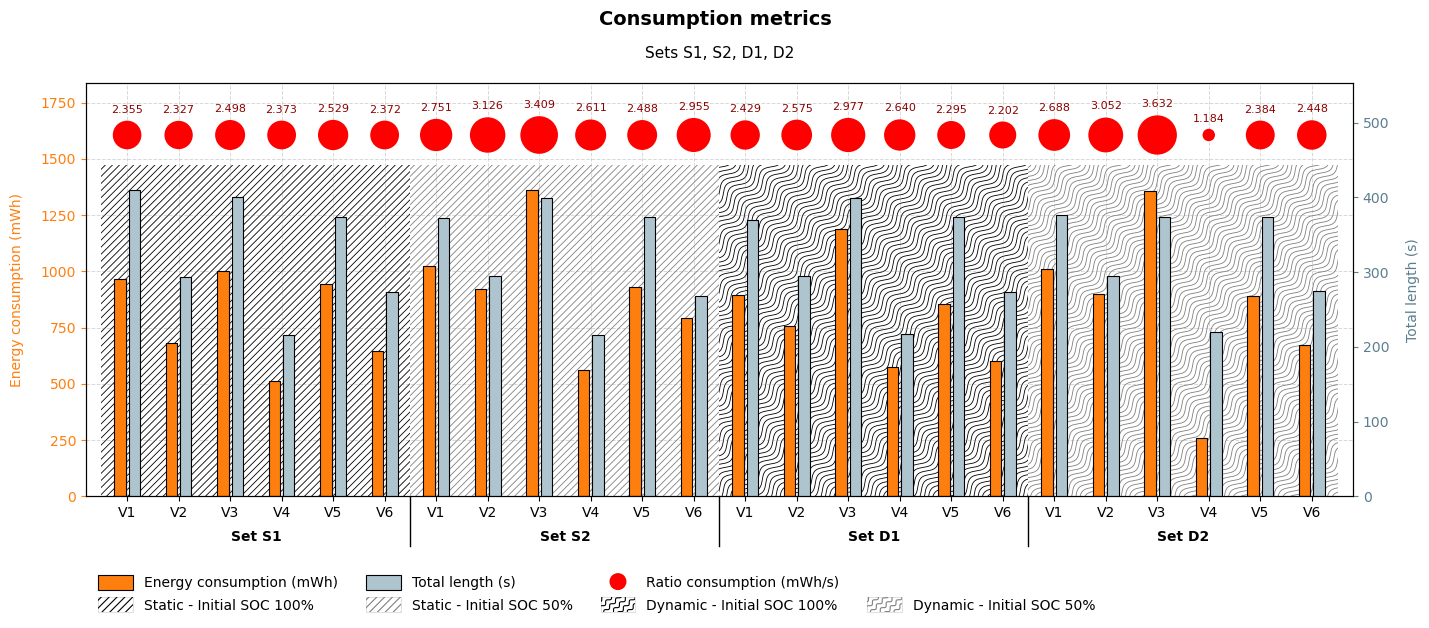

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# Sets to include on the x-axis (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2"}

# Colors
CONS_COLOR = "tab:orange"        # energy consumption bars
LENGTH_COLOR = "#AEC4CE"         # total length bars (light blue-grey)
LENGTH_TEXT_COLOR = "#5B7F8E"    # darker blue-grey for the right axis text (readable)
BAR_EDGE = dict(edgecolor="black", linewidth=0.8)   # thin black outline on bars

# Background pattern per set (by final display name): (line color, curved?)
BG_PATTERNS = {
    "S1": ("black", False),   # straight diagonal, black
    "S2": ("gray",  False),   # straight diagonal, gray
    "D1": ("black", True),    # curved diagonal, black
    "D2": ("gray",  True),    # curved diagonal, gray
}

# Legend text for each background style: (line color, curved?, label)
PATTERN_LEGEND = [
    ("black", False, "Static - Initial SOC 100%"),
    ("gray",  False, "Static - Initial SOC 50%"),
    ("black", True,  "Dynamic - Initial SOC 100%"),
    ("gray",  True,  "Dynamic - Initial SOC 50%"),
]


def diagonal_lines(x0, y0, x1, y1, curved, spacing, amplitude, wavelength, n=600):
    """Points for 45° diagonal lines (straight or wavy) covering the box (x0, y0)-(x1, y1)."""
    d = np.array([1, 1]) / np.sqrt(2)    # direction along the lines
    p = np.array([-1, 1]) / np.sqrt(2)   # direction between lines
    corners = np.array([[x0, y0], [x1, y0], [x0, y1], [x1, y1]])
    c_min, c_max = (corners @ p).min(), (corners @ p).max()
    t_min, t_max = (corners @ d).min(), (corners @ d).max()
    t = np.linspace(t_min, t_max, n)
    wave = amplitude * np.sin(2 * np.pi * t / wavelength) if curved else np.zeros_like(t)
    for c in np.arange(c_min, c_max + spacing, spacing):
        yield np.outer(t, d) + np.outer(c + wave, p)


def diagonal_background(ax, x0, x1, color, curved=False, y_top=1.0,
                        spacing=0.05, amplitude=0.04, wavelength=0.35, lw=0.6):
    """Diagonal lines behind the bars between x0 and x1, from the bottom of the plot
    up to y_top (fraction of the axes height). spacing, amplitude, wavelength in inches."""
    fig = ax.figure
    pos = ax.get_position()
    W = pos.width * fig.get_figwidth()     # axes width in inches
    H = pos.height * fig.get_figheight()   # axes height in inches
    xlo, xhi = ax.get_xlim()
    fx0, fx1 = (x0 - xlo) / (xhi - xlo), (x1 - xlo) / (xhi - xlo)

    clip = Rectangle((fx0, 0), fx1 - fx0, y_top, transform=ax.transAxes)
    for pts in diagonal_lines(fx0 * W, 0, fx1 * W, y_top * H, curved,
                              spacing, amplitude, wavelength):
        line, = ax.plot(pts[:, 0] / W, pts[:, 1] / H, transform=ax.transAxes,
                        color=color, linewidth=lw, zorder=0.2)
        line.set_clip_path(clip)


class DiagonalHandler(HandlerBase):
    """Legend swatch showing the diagonal pattern (straight or curved)."""
    def __init__(self, color, curved):
        super().__init__()
        self.color, self.curved = color, curved

    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        x0, y0 = -xdescent, -ydescent
        box = Rectangle((x0, y0), width, height, facecolor="white",
                        edgecolor="lightgray", linewidth=0.5, transform=trans)
        clip = Rectangle((x0, y0), width, height, transform=trans)
        artists = [box]
        for pts in diagonal_lines(x0, y0, x0 + width, y0 + height, self.curved,
                                  spacing=4, amplitude=1.0, wavelength=6, n=100):
            ln = Line2D(pts[:, 0], pts[:, 1], color=self.color, linewidth=0.8,
                        transform=trans)
            ln.set_clip_path(clip)
            artists.append(ln)
        return artists


subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and rate
bar_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        **{
            "user_state": ("user_state", "first"),
            "total_consumption (mWh)": ("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
            "total_length (s)": ("Video Position (s)", lambda p: p.max() - p.min()),
        }
    )
    .reset_index()
)
bar_df["consumption_rate (mWh/s)"] = (
    bar_df["total_consumption (mWh)"] / bar_df["total_length (s)"].replace(0, np.nan)
)

# Order: by set number, then video number
bar_df = bar_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names: S + number for Static sets, D + number for Dynamic sets, then rename
bar_df["set_name"] = bar_df["user_state"].map(STATE_PREFIX).fillna("?") + bar_df["set_id"].str[1:]
bar_df["set_name"] = bar_df["set_name"].replace(NAME_RENAME)   # D3 -> D1, D4 -> D2

x = np.arange(len(bar_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue-grey bars
offset = width / 2 + gap / 2

cons = bar_df["total_consumption (mWh)"]
length = bar_df["total_length (s)"]
ratio = bar_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(max(12, len(x) * 0.6), 6.5))   # wider for more bars
ax2 = ax1.twinx()   # second y-axis on the right

# Gray grid behind the bars
ax1.set_axisbelow(True)
ax1.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bars with a thin black outline
bars1 = ax1.bar(x - offset, cons, width, color=CONS_COLOR, **BAR_EDGE,
                label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width, color=LENGTH_COLOR, **BAR_EDGE,
                label="Total length (s)")

# Leave free space at the top of both axes for the circles
headroom = 1.35
ax1.set_ylim(0, cons.max() * headroom)
ax2.set_ylim(0, length.max() * headroom)

# Circle size scaled linearly with the ratio (smallest -> min_size, largest -> max_size)
min_size, max_size = 80, 800
r_min, r_max = ratio.min(), ratio.max()
if r_max > r_min:
    sizes = min_size + (ratio - r_min) / (r_max - r_min) * (max_size - min_size)
else:
    sizes = np.full(len(ratio), (min_size + max_size) / 2)

# Solid red circles, no outline
circle_y = cons.max() * 1.18
circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3,
                      label="Ratio consumption (mWh/s)")

# Ratio value horizontal, centered, just above each circle (regular weight)
for xi, r, sz in zip(x, ratio, sizes):
    radius_pt = np.sqrt(sz / np.pi)   # circle radius in points
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, radius_pt + 3),
                 textcoords="offset points", ha="center", va="bottom",
                 fontsize=8, fontweight="normal", color="darkred")

# Same small margin on both sides of the bars
side_margin = 0.8
ax1.set_xlim(-side_margin, len(x) - 1 + side_margin)

# Axes labels, colored to match their bars, a bit further from the axes
ax1.set_ylabel("Energy consumption (mWh)", color=CONS_COLOR, labelpad=12)
ax2.set_ylabel("Total length (s)", color=LENGTH_TEXT_COLOR, labelpad=12)
ax1.tick_params(axis="y", colors=CONS_COLOR)
ax2.tick_params(axis="y", colors=LENGTH_TEXT_COLOR)

# Tick labels V1..V6, with "Set S1", "Set S2", ... centered below each group
ax1.set_xticks(x)
ax1.set_xticklabels(bar_df["vd_id"])
groups = list(bar_df.groupby("set_name", sort=False))
for name, g in groups:
    ax1.text(g.index.to_numpy().mean(), -0.08, f"Set {name}",
             transform=ax1.get_xaxis_transform(), ha="center", va="top",
             fontsize=10, fontweight="bold")

# Short separator lines below the x-axis between sets
for _, g in groups[:-1]:
    sep_x = g.index.max() + 0.5
    ax1.plot([sep_x, sep_x], [0, -0.12], transform=ax1.get_xaxis_transform(),
             color="black", linewidth=1, clip_on=False)

# Legend: metrics on the first row, background patterns on the second
pattern_handles = [Patch(label=label) for _, _, label in PATTERN_LEGEND]
handler_map = {h: DiagonalHandler(color, curved)
               for h, (color, curved, _) in zip(pattern_handles, PATTERN_LEGEND)}
blank = Patch(visible=False, label="")

# Legend fills column by column, so interleave to get two clean rows
handles = [bars1, pattern_handles[0],
           bars2, pattern_handles[1],
           circles, pattern_handles[2],
           blank, pattern_handles[3]]
leg = ax1.legend(handles=handles, handler_map=handler_map,
                 loc="upper left", bbox_to_anchor=(0, -0.16), ncol=4,
                 frameon=False, handlelength=2.5, handleheight=1.3)
leg.legend_handles[handles.index(circles)].set_sizes([150])

# Subtitle with display names, e.g. "Sets S1, S2, D1, D2" (black, raised above the box)
display_sets = bar_df.drop_duplicates("set_id")["set_name"].tolist()
fig.suptitle("Consumption metrics", fontsize=14, fontweight="bold")
ax1.set_title(f"Sets {', '.join(display_sets)}", fontsize=11, color="black", pad=18)
fig.tight_layout()

# Where the patterns stop: just below the bottom of the largest circle
axes_h_in = ax1.get_position().height * fig.get_figheight()   # axes height in inches
circle_frac = circle_y / ax1.get_ylim()[1]                     # circle row, fraction of height
max_radius_in = np.sqrt(max_size / np.pi) / 72                 # largest circle radius, inches
pattern_gap_in = 0.08                                          # extra space below the circles
y_top = circle_frac - (max_radius_in + pattern_gap_in) / axes_h_in

# Background patterns per set (drawn after the layout is final)
for name, g in groups:
    if name in BG_PATTERNS:
        color, curved = BG_PATTERNS[name]
        diagonal_background(ax1, g.index.min() - 0.5, g.index.max() + 0.5,
                            color=color, curved=curved, y_top=y_top)

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / "Consumption_metrics_selected_sets.pdf", dpi=300, bbox_inches="tight")

plt.show()

### 3. LAST GRAPH (RENAMED) & UPDATED VISUALS:

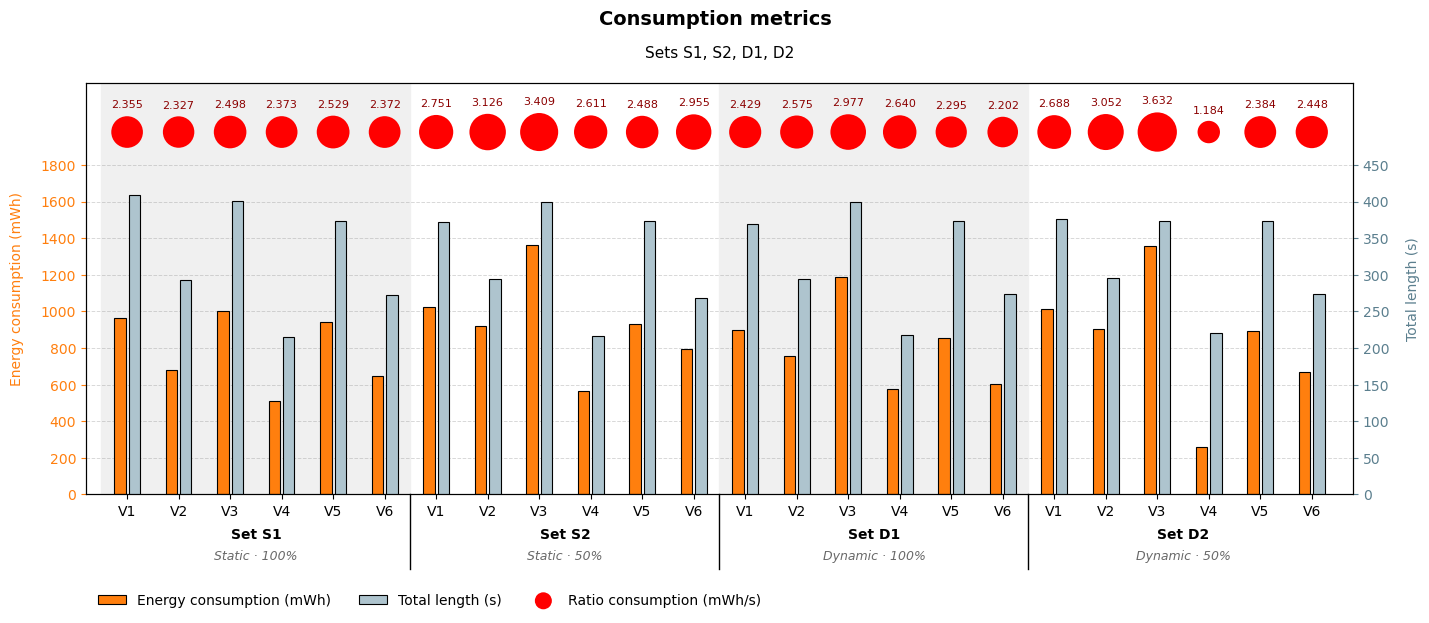

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import FixedLocator

# Sets to include on the x-axis (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2"}

# Condition shown under each set name (by final display name)
CONDITION = {
    "S1": "Static · 100%",
    "S2": "Static · 50%",
    "D1": "Dynamic · 100%",
    "D2": "Dynamic · 50%",
}

# Colors
CONS_COLOR = "tab:orange"        # energy consumption bars
LENGTH_COLOR = "#AEC4CE"         # total length bars (light blue-grey)
LENGTH_TEXT_COLOR = "#5B7F8E"    # darker blue-grey for the right axis text (readable)
BAR_EDGE = dict(edgecolor="black", linewidth=0.8)   # thin black outline on bars
BAND_COLOR = "#F0F0F0"           # light band behind every other set


def nice_step(raw):
    """Smallest 'nice' step (1, 2, 2.5, 4 or 5 x 10^k) that is >= raw."""
    exp = 10 ** np.floor(np.log10(raw))
    for m in (1, 2, 2.5, 4, 5, 10):
        if m * exp >= raw:
            return m * exp


subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and rate
bar_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        **{
            "user_state": ("user_state", "first"),
            "total_consumption (mWh)": ("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
            "total_length (s)": ("Video Position (s)", lambda p: p.max() - p.min()),
        }
    )
    .reset_index()
)
bar_df["consumption_rate (mWh/s)"] = (
    bar_df["total_consumption (mWh)"] / bar_df["total_length (s)"].replace(0, np.nan)
)

# Order: by set number, then video number
bar_df = bar_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names: S + number for Static sets, D + number for Dynamic sets, then rename
bar_df["set_name"] = bar_df["user_state"].map(STATE_PREFIX).fillna("?") + bar_df["set_id"].str[1:]
bar_df["set_name"] = bar_df["set_name"].replace(NAME_RENAME)   # D3 -> D1, D4 -> D2

x = np.arange(len(bar_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue-grey bars
offset = width / 2 + gap / 2

cons = bar_df["total_consumption (mWh)"]
length = bar_df["total_length (s)"]
ratio = bar_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(max(12, len(x) * 0.6), 6.5))   # wider for more bars
ax2 = ax1.twinx()   # second y-axis on the right

# Horizontal grid lines only (they stop at the top grid line, see below)
ax1.set_axisbelow(True)
ax1.grid(True, axis="y", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bars with a thin black outline
bars1 = ax1.bar(x - offset, cons, width, color=CONS_COLOR, **BAR_EDGE,
                label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width, color=LENGTH_COLOR, **BAR_EDGE,
                label="Total length (s)")

# ---------- Aligned y-axes ----------
# Bar area: same number of intervals on both sides, each with a "nice" step,
# so every right-axis tick falls exactly on a grid line
bar_pad = 1.05                          # small space above the tallest bar
min_intervals, max_intervals = 7, 12    # how many grid intervals you want (range)

need1 = cons.max() * bar_pad
need2 = length.max() * bar_pad

best = None
for n in range(min_intervals, max_intervals + 1):
    s1 = nice_step(need1 / n)
    s2 = nice_step(need2 / n)
    waste = (n * s1) / need1 + (n * s2) / need2   # how much the axes overshoot (lower = tighter)
    if best is None or waste < best[0]:
        best = (waste, n, s1, s2)
_, n_int, step1, step2 = best

grid_top1 = n_int * step1               # top grid line, left axis  (e.g. 1800)
grid_top2 = n_int * step2               # top grid line, right axis (e.g. 450)

# Free strip above the top grid line for the ratio circles (fraction of the plot height)
circle_zone = 0.2
ax1.set_ylim(0, grid_top1 / (1 - circle_zone))
ax2.set_ylim(0, grid_top2 / (1 - circle_zone))

# Numbered ticks (and grid lines) only up to the top grid line
ax1.yaxis.set_major_locator(FixedLocator(np.arange(0, grid_top1 + step1 / 2, step1)))
ax2.yaxis.set_major_locator(FixedLocator(np.arange(0, grid_top2 + step2 / 2, step2)))

# ---------- Ratio circles in the free strip ----------
# Circle AREA proportional to the ratio (a ratio twice as large -> circle twice the area)
max_size = 800                                  # area (points²) of the largest ratio
sizes = (ratio / ratio.max() * max_size).fillna(0)

top1 = ax1.get_ylim()[1]
circle_y = grid_top1 + (top1 - grid_top1) * 0.4   # lower part of the strip, labels go above

circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3, clip_on=False,
                      label="Ratio consumption (mWh/s)")

# Ratio value horizontal, centered, just above each circle (regular weight)
for xi, r, sz in zip(x, ratio, sizes):
    radius_pt = np.sqrt(sz / np.pi)   # circle radius in points
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, radius_pt + 3),
                 textcoords="offset points", ha="center", va="bottom",
                 fontsize=8, fontweight="normal", color="darkred")

# Same small margin on both sides of the bars
side_margin = 0.8
ax1.set_xlim(-side_margin, len(x) - 1 + side_margin)

# Axes labels, colored to match their bars, a bit further from the axes
ax1.set_ylabel("Energy consumption (mWh)", color=CONS_COLOR, labelpad=12)
ax2.set_ylabel("Total length (s)", color=LENGTH_TEXT_COLOR, labelpad=12)
ax1.tick_params(axis="y", colors=CONS_COLOR)
ax2.tick_params(axis="y", colors=LENGTH_TEXT_COLOR)

# Tick labels V1..V6, with the set name and its condition centered below each group,
# and a light band (bar area only) behind every other set
ax1.set_xticks(x)
ax1.set_xticklabels(bar_df["vd_id"])
groups = list(bar_df.groupby("set_name", sort=False))
for i, (name, g) in enumerate(groups):
    x_mid = g.index.to_numpy().mean()
    ax1.text(x_mid, -0.08, f"Set {name}", transform=ax1.get_xaxis_transform(),
             ha="center", va="top", fontsize=10, fontweight="bold")
    ax1.text(x_mid, -0.135, CONDITION.get(name, ""), transform=ax1.get_xaxis_transform(),
             ha="center", va="top", fontsize=9, style="italic", color="dimgray")
    if i % 2 == 0:
        ax1.axvspan(g.index.min() - 0.5, g.index.max() + 0.5,
                    color=BAND_COLOR, zorder=0)

# Short separator lines below the x-axis between sets (covering both label lines)
for _, g in groups[:-1]:
    sep_x = g.index.max() + 0.5
    ax1.plot([sep_x, sep_x], [0, -0.18], transform=ax1.get_xaxis_transform(),
             color="black", linewidth=1, clip_on=False)

# Legend: the three metrics in one row, below the set labels
leg = ax1.legend(handles=[bars1, bars2, circles], loc="upper left",
                 bbox_to_anchor=(0, -0.21), ncol=3, frameon=False)
leg.legend_handles[2].set_sizes([150])

# Subtitle with display names, e.g. "Sets S1, S2, D1, D2" (black, raised above the box)
display_sets = bar_df.drop_duplicates("set_id")["set_name"].tolist()
fig.suptitle("Consumption metrics", fontsize=14, fontweight="bold")
ax1.set_title(f"Sets {', '.join(display_sets)}", fontsize=11, color="black", pad=18)
fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / "Consumption_metrics_selected_sets.pdf", dpi=300, bbox_inches="tight")

plt.show()

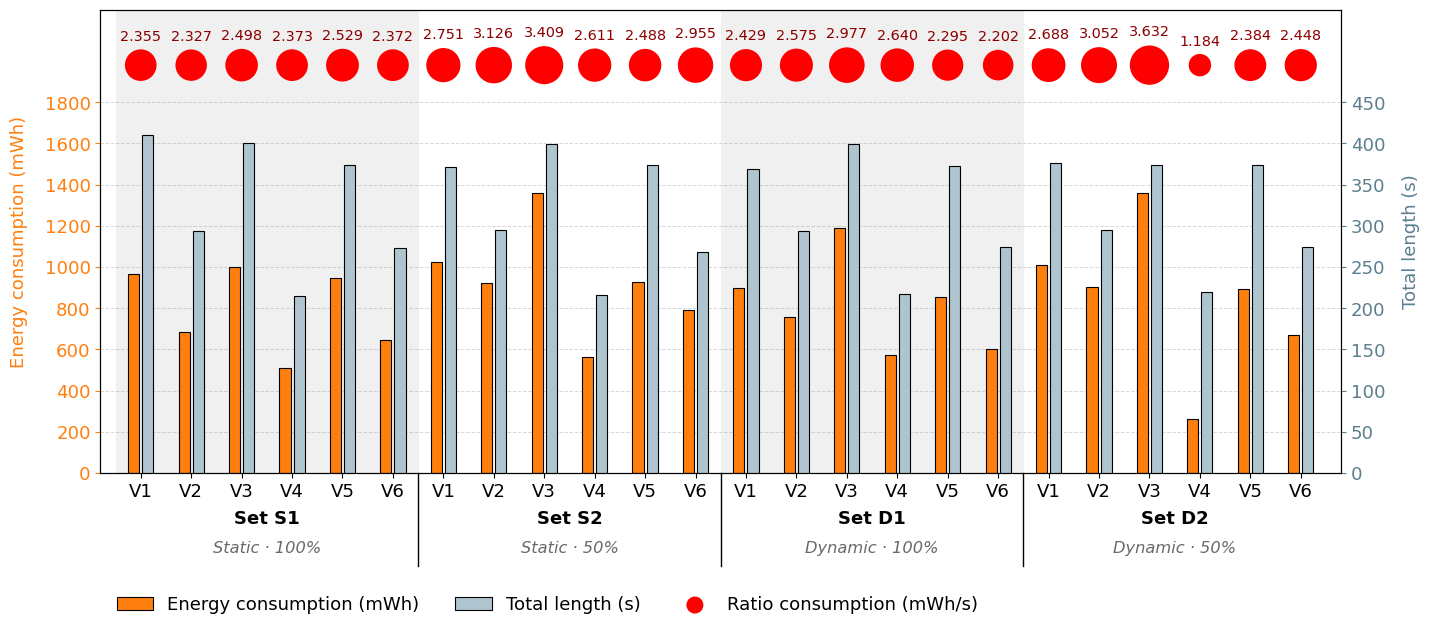

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.ticker import FixedLocator

# Sets to include on the x-axis (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2"}

# Condition shown under each set name (by final display name)
CONDITION = {
    "S1": "Static · 100%",
    "S2": "Static · 50%",
    "D1": "Dynamic · 100%",
    "D2": "Dynamic · 50%",
}

# Colors
CONS_COLOR = "tab:orange"        # energy consumption bars
LENGTH_COLOR = "#AEC4CE"         # total length bars (light blue-grey)
LENGTH_TEXT_COLOR = "#5B7F8E"    # darker blue-grey for the right axis text (readable)
BAR_EDGE = dict(edgecolor="black", linewidth=0.8)   # thin black outline on bars
BAND_COLOR = "#F0F0F0"           # light band behind every other set

# Text sizes (1.3x the previous sizes)
SCALE = 1.3
AXIS_LABEL_SIZE = 10 * SCALE     # axis titles
TICK_SIZE = 10 * SCALE           # numbers on the axes and V1..V6
RATIO_SIZE = 8 * SCALE           # ratio values above the circles
SET_NAME_SIZE = 10 * SCALE       # "Set S1" etc.
CONDITION_SIZE = 9 * SCALE       # "Static · 100%" etc.
LEGEND_SIZE = 10 * SCALE         # legend text


def nice_step(raw):
    """Smallest 'nice' step (1, 2, 2.5, 4 or 5 x 10^k) that is >= raw."""
    exp = 10 ** np.floor(np.log10(raw))
    for m in (1, 2, 2.5, 4, 5, 10):
        if m * exp >= raw:
            return m * exp


subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and rate
bar_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        **{
            "user_state": ("user_state", "first"),
            "total_consumption (mWh)": ("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
            "total_length (s)": ("Video Position (s)", lambda p: p.max() - p.min()),
        }
    )
    .reset_index()
)
bar_df["consumption_rate (mWh/s)"] = (
    bar_df["total_consumption (mWh)"] / bar_df["total_length (s)"].replace(0, np.nan)
)

# Order: by set number, then video number
bar_df = bar_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names: S + number for Static sets, D + number for Dynamic sets, then rename
bar_df["set_name"] = bar_df["user_state"].map(STATE_PREFIX).fillna("?") + bar_df["set_id"].str[1:]
bar_df["set_name"] = bar_df["set_name"].replace(NAME_RENAME)   # D3 -> D1, D4 -> D2

x = np.arange(len(bar_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue-grey bars
offset = width / 2 + gap / 2

cons = bar_df["total_consumption (mWh)"]
length = bar_df["total_length (s)"]
ratio = bar_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(max(12, len(x) * 0.6), 6.5))   # wider for more bars
ax2 = ax1.twinx()   # second y-axis on the right

# Horizontal grid lines only (they stop at the top grid line, see below)
ax1.set_axisbelow(True)
ax1.grid(True, axis="y", color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

# Bars with a thin black outline
bars1 = ax1.bar(x - offset, cons, width, color=CONS_COLOR, **BAR_EDGE,
                label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width, color=LENGTH_COLOR, **BAR_EDGE,
                label="Total length (s)")

# ---------- Aligned y-axes ----------
# Bar area: same number of intervals on both sides, each with a "nice" step,
# so every right-axis tick falls exactly on a grid line
bar_pad = 1.05                          # small space above the tallest bar
min_intervals, max_intervals = 7, 12    # how many grid intervals you want (range)

need1 = cons.max() * bar_pad
need2 = length.max() * bar_pad

best = None
for n in range(min_intervals, max_intervals + 1):
    s1 = nice_step(need1 / n)
    s2 = nice_step(need2 / n)
    waste = (n * s1) / need1 + (n * s2) / need2   # how much the axes overshoot (lower = tighter)
    if best is None or waste < best[0]:
        best = (waste, n, s1, s2)
_, n_int, step1, step2 = best

grid_top1 = n_int * step1               # top grid line, left axis  (e.g. 1800)
grid_top2 = n_int * step2               # top grid line, right axis (e.g. 450)

# Free strip above the top grid line for the ratio circles (fraction of the plot height)
circle_zone = 0.2
ax1.set_ylim(0, grid_top1 / (1 - circle_zone))
ax2.set_ylim(0, grid_top2 / (1 - circle_zone))

# Numbered ticks (and grid lines) only up to the top grid line
ax1.yaxis.set_major_locator(FixedLocator(np.arange(0, grid_top1 + step1 / 2, step1)))
ax2.yaxis.set_major_locator(FixedLocator(np.arange(0, grid_top2 + step2 / 2, step2)))

# ---------- Ratio circles in the free strip ----------
# Circle AREA proportional to the ratio (a ratio twice as large -> circle twice the area)
max_size = 800                                  # area (points²) of the largest ratio
sizes = (ratio / ratio.max() * max_size).fillna(0)

top1 = ax1.get_ylim()[1]
circle_y = grid_top1 + (top1 - grid_top1) * 0.4   # lower part of the strip, labels go above

circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3, clip_on=False,
                      label="Ratio consumption (mWh/s)")

# Ratio value horizontal, centered, just above each circle (regular weight)
for xi, r, sz in zip(x, ratio, sizes):
    radius_pt = np.sqrt(sz / np.pi)   # circle radius in points
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, radius_pt + 3),
                 textcoords="offset points", ha="center", va="bottom",
                 fontsize=RATIO_SIZE, fontweight="normal", color="darkred")

# Same small margin on both sides of the bars
side_margin = 0.8
ax1.set_xlim(-side_margin, len(x) - 1 + side_margin)

# Axes labels, colored to match their bars, a bit further from the axes
ax1.set_ylabel("Energy consumption (mWh)", color=CONS_COLOR, labelpad=12,
               fontsize=AXIS_LABEL_SIZE)
ax2.set_ylabel("Total length (s)", color=LENGTH_TEXT_COLOR, labelpad=12,
               fontsize=AXIS_LABEL_SIZE)
ax1.tick_params(axis="y", colors=CONS_COLOR, labelsize=TICK_SIZE)
ax2.tick_params(axis="y", colors=LENGTH_TEXT_COLOR, labelsize=TICK_SIZE)
ax1.tick_params(axis="x", labelsize=TICK_SIZE)

# Tick labels V1..V6, with the set name and its condition centered below each group,
# and a light band (bar area only) behind every other set
ax1.set_xticks(x)
ax1.set_xticklabels(bar_df["vd_id"])
groups = list(bar_df.groupby("set_name", sort=False))
for i, (name, g) in enumerate(groups):
    x_mid = g.index.to_numpy().mean()
    ax1.text(x_mid, -0.08, f"Set {name}", transform=ax1.get_xaxis_transform(),
             ha="center", va="top", fontsize=SET_NAME_SIZE, fontweight="bold")
    ax1.text(x_mid, -0.145, CONDITION.get(name, ""), transform=ax1.get_xaxis_transform(),
             ha="center", va="top", fontsize=CONDITION_SIZE, style="italic", color="dimgray")
    if i % 2 == 0:
        ax1.axvspan(g.index.min() - 0.5, g.index.max() + 0.5,
                    color=BAND_COLOR, zorder=0)

# Short separator lines below the x-axis between sets (covering both label lines)
for _, g in groups[:-1]:
    sep_x = g.index.max() + 0.5
    ax1.plot([sep_x, sep_x], [0, -0.20], transform=ax1.get_xaxis_transform(),
             color="black", linewidth=1, clip_on=False)

# Legend: the three metrics in one row, below the set labels
leg = ax1.legend(handles=[bars1, bars2, circles], loc="upper left",
                 bbox_to_anchor=(0, -0.23), ncol=3, frameon=False,
                 fontsize=LEGEND_SIZE)
leg.legend_handles[2].set_sizes([150])

fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / "Consumption_metrics_selected_sets.pdf", dpi=300, bbox_inches="tight")

plt.show()

## 4. TABLES (Avgerage and deviation):

### 4.1 Comparison of Videos within same Set:

#### It contains: 
- Diff. from average (mWh/s): the ratio minus the set’s average. Positive means above average, negative means below.
- Std. deviations from average: that difference divided by the standard deviation. Values between −1 and +1 are typical, while values beyond about ±2 stand out as unusual. With only six videos per set, treat this as a rough guide rather than a formal outlier test.

In [12]:
import numpy as np
import pandas as pd

# Sets to include (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2"}

subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

# One row per (set, video): state, consumption, length and ratio (same as the graph)
ratio_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    .reset_index()
)
ratio_df["ratio"] = ratio_df["energy"] / ratio_df["video_length"].replace(0, np.nan)

# Order: by set number, then video number
ratio_df = ratio_df.sort_values(
    ["set_id", "vd_id"], key=lambda c: c.str[1:].astype(int)
).reset_index(drop=True)

# Display names (S1, S2, D1, D2)
ratio_df["set_name"] = (ratio_df["user_state"].map(STATE_PREFIX).fillna("?")
                        + ratio_df["set_id"].str[1:]).replace(NAME_RENAME)

# One table per set: Video | Ratio | Difference from average | Std. deviations from average
set_tables = {}
for name, g in ratio_df.groupby("set_name", sort=False):
    mean = g["ratio"].mean()
    std = g["ratio"].std()   # sample standard deviation (n - 1)

    t = pd.DataFrame({
        "Video": g["vd_id"].values,
        "Ratio (mWh/s)": g["ratio"].values,
        "Diff. from average (mWh/s)": (g["ratio"] - mean).values,
        "Std. deviations from average": ((g["ratio"] - mean) / std).values,
    })
    stats = pd.DataFrame({
        "Video": ["Average", "Std. deviation"],
        "Ratio (mWh/s)": [mean, std],
    })
    t = pd.concat([t, stats], ignore_index=True).round(3)
    t = t.astype(object).where(t.notna(), "")   # leave the extra columns blank on the stats rows
    set_tables[name] = t

    print(f"Set {name}")
    display(t)

Set S1


,Video,Ratio (mWh/s),Diff. from average (mWh/s),Std. deviations from average
0,V1,2.355,-0.054,-0.649
1,V2,2.327,-0.082,-0.984
2,V3,2.498,0.089,1.072
3,V4,2.373,-0.036,-0.433
4,V5,2.529,0.12,1.44
5,V6,2.372,-0.037,-0.446
6,Average,2.409,,
7,Std. deviation,0.083,,


Set S2


,Video,Ratio (mWh/s),Diff. from average (mWh/s),Std. deviations from average
0,V1,2.751,-0.139,-0.405
1,V2,3.126,0.236,0.689
2,V3,3.409,0.519,1.513
3,V4,2.611,-0.279,-0.814
4,V5,2.488,-0.402,-1.172
5,V6,2.955,0.065,0.189
6,Average,2.89,,
7,Std. deviation,0.343,,


Set D1


,Video,Ratio (mWh/s),Diff. from average (mWh/s),Std. deviations from average
0,V1,2.429,-0.09,-0.325
1,V2,2.575,0.055,0.199
2,V3,2.977,0.457,1.645
3,V4,2.64,0.12,0.433
4,V5,2.295,-0.225,-0.809
5,V6,2.202,-0.318,-1.143
6,Average,2.52,,
7,Std. deviation,0.278,,


Set D2


,Video,Ratio (mWh/s),Diff. from average (mWh/s),Std. deviations from average
0,V1,2.688,0.123,0.151
1,V2,3.052,0.488,0.596
2,V3,3.632,1.067,1.305
3,V4,1.184,-1.38,-1.688
4,V5,2.384,-0.181,-0.221
5,V6,2.448,-0.117,-0.143
6,Average,2.564,,
7,Std. deviation,0.818,,


### 4.2 Comparison between Sets:

#### It contains: 
- Video:V1–V6.
- Ratio of the first set.
- Ratio of the second set.
- Difference (first − second). Positive means the first set used more energy per second on that video.
- Std. deviations from average diff.: how far each video’s difference is from the average difference, in standard deviations (the same idea as the z-score in the previous tables). Values beyond about ±2 stand out.

In [13]:
from itertools import combinations

# Ratios in wide form: one row per video, one column per set
wide = ratio_df.pivot(index="vd_id", columns="set_name", values="ratio")
wide = wide.loc[sorted(wide.index, key=lambda v: int(v[1:]))]   # V1, V2, ..., V6

set_order = ["S1", "S2", "D1", "D2"]
set_order = [s for s in set_order if s in wide.columns]

pair_tables = {}
for a, b in combinations(set_order, 2):
    diff = wide[a] - wide[b]
    mean_diff = diff.mean()
    std_diff = diff.std()   # sample standard deviation (n - 1)

    t = pd.DataFrame({
        "Video": wide.index,
        f"Ratio {a} (mWh/s)": wide[a].values,
        f"Ratio {b} (mWh/s)": wide[b].values,
        f"Difference {a} − {b}": diff.values,
        "Std. deviations from average diff.": ((diff - mean_diff) / std_diff).values,
    })
    stats = pd.DataFrame({
        "Video": ["Total |difference|", "Average difference", "Std. deviation"],
        f"Difference {a} − {b}": [diff.abs().sum(), mean_diff, std_diff],
    })
    t = pd.concat([t, stats], ignore_index=True).round(3)
    t = t.astype(object).where(t.notna(), "")   # blank cells on the summary rows
    pair_tables[(a, b)] = t

    print(f"Set {a} vs. Set {b}")
    display(t)

Set S1 vs. Set S2


,Video,Ratio S1 (mWh/s),Ratio S2 (mWh/s),Difference S1 − S2,Std. deviations from average diff.
0,V1,2.355,2.751,-0.397,0.238
1,V2,2.327,3.126,-0.799,-0.893
2,V3,2.498,3.409,-0.911,-1.206
3,V4,2.373,2.611,-0.238,0.682
4,V5,2.529,2.488,0.041,1.465
5,V6,2.372,2.955,-0.583,-0.286
6,Total |difference|,,,2.969,
7,Average difference,,,-0.481,
8,Std. deviation,,,0.356,


Set S1 vs. Set D1


,Video,Ratio S1 (mWh/s),Ratio D1 (mWh/s),Difference S1 − D1,Std. deviations from average diff.
0,V1,2.355,2.429,-0.075,0.132
1,V2,2.327,2.575,-0.248,-0.5
2,V3,2.498,2.977,-0.479,-1.339
3,V4,2.373,2.64,-0.267,-0.569
4,V5,2.529,2.295,0.234,1.255
5,V6,2.372,2.202,0.17,1.021
6,Total |difference|,,,1.473,
7,Average difference,,,-0.111,
8,Std. deviation,,,0.275,


Set S1 vs. Set D2


,Video,Ratio S1 (mWh/s),Ratio D2 (mWh/s),Difference S1 − D2,Std. deviations from average diff.
0,V1,2.355,2.688,-0.333,-0.221
1,V2,2.327,3.052,-0.726,-0.71
2,V3,2.498,3.632,-1.134,-1.219
3,V4,2.373,1.184,1.188,1.676
4,V5,2.529,2.384,0.145,0.375
5,V6,2.372,2.448,-0.076,0.099
6,Total |difference|,,,3.602,
7,Average difference,,,-0.156,
8,Std. deviation,,,0.802,


... (2 outputs left out)

Set S2 vs. Set D2


,Video,Ratio S2 (mWh/s),Ratio D2 (mWh/s),Difference S2 − D2,Std. deviations from average diff.
0,V1,2.751,2.688,0.064,-0.446
1,V2,3.126,3.052,0.074,-0.428
2,V3,3.409,3.632,-0.223,-0.933
3,V4,2.611,1.184,1.427,1.874
4,V5,2.488,2.384,0.104,-0.376
5,V6,2.955,2.448,0.507,0.309
6,Total |difference|,,,2.398,
7,Average difference,,,0.326,
8,Std. deviation,,,0.588,


Set D1 vs. Set D2


,Video,Ratio D1 (mWh/s),Ratio D2 (mWh/s),Difference D1 − D2,Std. deviations from average diff.
0,V1,2.429,2.688,-0.258,-0.28
1,V2,2.575,3.052,-0.477,-0.568
2,V3,2.977,3.632,-0.655,-0.801
3,V4,2.64,1.184,1.456,1.971
4,V5,2.295,2.384,-0.089,-0.058
5,V6,2.202,2.448,-0.246,-0.264
6,Total |difference|,,,3.181,
7,Average difference,,,-0.045,
8,Std. deviation,,,0.761,


# BETA

#### Note: 
need to install pip install statsmodels (in terminal)

In [14]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ---------------- Data: one ratio per (set, video) ----------------

# Sets to include (original IDs as they appear in the data)
SETS = ["S1", "S2", "S3", "S4"]

# Display prefix by user state: ST -> S, DY -> D
STATE_PREFIX = {"ST": "S", "DY": "D"}

# Final display names (S/D name -> new name)
NAME_RENAME = {"S1": "S1", "S2": "S2", "D3": "D1", "D4": "D2"}

# Experimental condition of each set (by final display name)
CONDITION_INFO = {
    "S1": ("Static", 100),
    "S2": ("Static", 50),
    "D1": ("Dynamic", 100),
    "D2": ("Dynamic", 50),
}

subset = df_all[df_all["set_id"].isin(SETS) & (df_all["user_state"] != "SQ")]

reg_df = (
    subset.groupby(["set_id", "vd_id"])
    .agg(
        user_state=("user_state", "first"),
        energy=("Accumulated Power (mWh)", lambda p: p.max() - p.min()),
        video_length=("Video Position (s)", lambda p: p.max() - p.min()),
    )
    .reset_index()
)
reg_df["ratio"] = reg_df["energy"] / reg_df["video_length"].replace(0, np.nan)
reg_df["set_name"] = (reg_df["user_state"].map(STATE_PREFIX).fillna("?")
                      + reg_df["set_id"].str[1:]).replace(NAME_RENAME)
reg_df["mode"] = reg_df["set_name"].map(lambda s: CONDITION_INFO[s][0])
reg_df["soc"] = reg_df["set_name"].map(lambda s: CONDITION_INFO[s][1])
reg_df = reg_df.dropna(subset=["ratio"])

# patsy (used by statsmodels formulas) can't read pandas' new string type,
# so convert text columns to plain objects
for col in ["mode", "vd_id", "set_name", "set_id", "user_state"]:
    reg_df[col] = reg_df[col].astype(object)

print(f"{len(reg_df)} observations "
      f"({reg_df['set_name'].nunique()} sets x {reg_df['vd_id'].nunique()} videos)")

# ---------------- Descriptive: average ratio per condition ----------------

desc = (reg_df.groupby(["mode", "soc"])["ratio"]
        .agg(["mean", "std", "count"])
        .round(3)
        .rename(columns={"mean": "Mean ratio (mWh/s)", "std": "Std. deviation", "count": "N videos"}))
print("\nAverage ratio per condition")
display(desc)

# ---------------- Regression ----------------
# Reference levels: Static play, 100% initial SOC, video V1
FORMULA = ("ratio ~ C(mode, Treatment('Static')) * C(soc, Treatment(100))"
           " + C(vd_id, Treatment('V1'))")

# Readable names for the model terms
TERM_NAMES = {
    "Intercept": "Intercept (Static, 100%, V1)",
    "C(mode, Treatment('Static'))[T.Dynamic]": "Dynamic (vs. Static)",
    "C(soc, Treatment(100))[T.50]": "SOC 50% (vs. 100%)",
    "C(mode, Treatment('Static'))[T.Dynamic]:C(soc, Treatment(100))[T.50]":
        "Interaction: Dynamic x SOC 50%",
}


def beta_table(model):
    """Betas with standard errors, 95% confidence intervals and p-values."""
    ci = model.conf_int()
    t = pd.DataFrame({
        "Beta": model.params,
        "Std. error": model.bse,
        "95% CI low": ci[0],
        "95% CI high": ci[1],
        "p-value": model.pvalues,
    })
    t.index = [TERM_NAMES.get(term, term.replace("C(vd_id, Treatment('V1'))[T.", "Video ")
                                         .replace("]", " (vs. V1)"))
               for term in t.index]
    return t.round(4)


model = smf.ols(FORMULA, data=reg_df).fit()

print("\nRegression: ratio explained by play mode, initial SOC, their interaction and the video")
print(f"R² = {model.rsquared:.3f}   adjusted R² = {model.rsquared_adj:.3f}   "
      f"N = {int(model.nobs)}   residual df = {int(model.df_resid)}")
display(beta_table(model))

# Full statsmodels output (optional, for reference)
# print(model.summary())

# ---------------- Sensitivity check: without D2-V4 ----------------
mask = ~((reg_df["set_name"] == "D2") & (reg_df["vd_id"] == "V4"))
model_no_outlier = smf.ols(FORMULA, data=reg_df[mask]).fit()

main_terms = [v for k, v in TERM_NAMES.items() if k != "Intercept"]
comparison = pd.DataFrame({
    "Beta (all data)": beta_table(model).loc[main_terms, "Beta"],
    "p-value (all data)": beta_table(model).loc[main_terms, "p-value"],
    "Beta (without D2-V4)": beta_table(model_no_outlier).loc[main_terms, "Beta"],
    "p-value (without D2-V4)": beta_table(model_no_outlier).loc[main_terms, "p-value"],
})
print("\nSensitivity check: main effects with and without D2-V4")
display(comparison)

24 observations (4 sets x 6 videos)

Average ratio per condition


Mean ratio (mWh/s)  Std. deviation  N videos
mode    soc                                              
Dynamic 50                2.564           0.818         6
        100               2.520           0.278         6
Static  50                2.890           0.343         6
        100               2.409           0.083         6


Regression: ratio explained by play mode, initial SOC, their interaction and the video
R² = 0.550   adjusted R² = 0.309   N = 24   residual df = 15


,Beta,Std. error,95% CI low,95% CI high,p-value
"Intercept (Static, 100%, V1)",2.3686,0.2402,1.8567,2.8806,0.0000
Dynamic (vs. Static),0.1109,0.2264,-0.3718,0.5936,0.6314
SOC 50% (vs. 100%),0.4813,0.2264,-0.0013,0.9640,0.0506
Video V2 (vs. V1),0.2143,0.2773,-0.3768,0.8055,0.4516
Video V3 (vs. V1),0.5732,0.2773,-0.0179,1.1644,0.0565
Video V4 (vs. V1),-0.3538,0.2773,-0.9449,0.2374,0.2215
Video V5 (vs. V1),-0.1320,0.2773,-0.7231,0.4592,0.6411
Video V6 (vs. V1),-0.0617,0.2773,-0.6528,0.5294,0.8269
Interaction: Dynamic x SOC 50%,-0.4364,0.3202,-1.1190,0.2462,0.1931



Sensitivity check: main effects with and without D2-V4


,Beta (all data),p-value (all data),Beta (without D2-V4),p-value (without D2-V4)
Dynamic (vs. Static),0.1109,0.6314,0.1109,0.4206
SOC 50% (vs. 100%),0.4813,0.0506,0.4813,0.0029
Interaction: Dynamic x SOC 50%,-0.4364,0.1931,-0.1733,0.3896
